## Project Title

## Credit Card Customer Churn Prediction Using Machine Learning

===========================================================================================================

Name : Silpa S Kumar

Organization : Entri Elevate

===========================================================================================================

Problem Statement : customer attrition is a major challenge for banks
                    retaining existing customers is important
                    identifying customers who are likely to leave can help the bank take preventive action
                    machine learning can identify patterns associated with customer attrition
                    the project will compare multiple classification algorithms to identify an effective prediction model

## OBJECTIVE

Main objective will be:
To develop and evaluate machine learning classification models that can predict whether a credit-card customer is likely to churn based on demographic, financial, account and transaction-related characteristics.

## DATA DESCRIPTION

Dataset
Credit Card Customers / BankChurners
Source
Kaggle
Number of records
10,127
Original columns
23
Target
Attrition_Flag
Two classes:
- Existing Customer
- Attrited Customer

The dataset contains demographic, account, credit and transaction-behavior information. Hugging Face
Important features

For example:
- Customer_Age
- Gender
- Dependent_count
- Education_Level
- Marital_Status
- Income_Category
- Card_Category
- Months_on_book
- Total_Relationship_Count
- Months_Inactive_12_mon
- Contacts_Count_12_mon
- Credit_Limit
- Total_Revolving_Bal
- Avg_Open_To_Buy
- Total_Amt_Chng_Q4_Q1
- Total_Trans_Amt
- Total_Trans_Ct
- Total_Ct_Chng_Q4_Q1
- Avg_Utilization_Ratio

===========================================================================================================

## Data Collection

===========================================================================================================

1. Download/load the dataset
2. Read the CSV
3. Display first five records
4. Check shape
5. Check column names
6. Check data types
7. Check missing values
8. Check duplicates
9. Examine the target distribution

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

In [3]:
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
# Load the dataset

df = pd.read_csv("C:\\Users\\silpa\\Downloads\\BankChurners.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:

df.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.99991
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.99994
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.99998
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.99987
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.99998


In [7]:
# Display last five rows

df.tail()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,3,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462,0.000191,0.999810
10123,710638233,Attrited Customer,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,4,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511,0.995270,0.004729
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,5,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000,0.997880,0.002118
10125,717406983,Attrited Customer,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,4,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000,0.996710,0.003294
10126,714337233,Attrited Customer,43,F,2,Graduate,Married,Less than $40K,Silver,25,6,2,4,10388.0,1961,8427.0,0.703,10294,61,0.649,0.189,0.996620,0.003377


In [8]:
# Check number of rows and columns

print("Number of rows:", df.shape[0])

Number of rows: 10127


In [9]:
print("Number of columns:", df.shape[1])

Number of columns: 23


In [10]:
# Display all column names

print("Column Names:")
for i, column in enumerate(df.columns, start=1):
    print(i, ":", column)

Column Names:
1 : CLIENTNUM
2 : Attrition_Flag
3 : Customer_Age
4 : Gender
5 : Dependent_count
6 : Education_Level
7 : Marital_Status
8 : Income_Category
9 : Card_Category
10 : Months_on_book
11 : Total_Relationship_Count
12 : Months_Inactive_12_mon
13 : Contacts_Count_12_mon
14 : Credit_Limit
15 : Total_Revolving_Bal
16 : Avg_Open_To_Buy
17 : Total_Amt_Chng_Q4_Q1
18 : Total_Trans_Amt
19 : Total_Trans_Ct
20 : Total_Ct_Chng_Q4_Q1
21 : Avg_Utilization_Ratio
22 : Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1
23 : Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2


In [11]:
df.dtypes

CLIENTNUM                                                                                                                               int64
Attrition_Flag                                                                                                                         object
Customer_Age                                                                                                                            int64
Gender                                                                                                                                 object
Dependent_count                                                                                                                         int64
Education_Level                                                                                                                        object
Marital_Status                                                                                                                         object
Income

In [12]:
# Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 23 columns):
 #   Column                                                                                                                              Non-Null Count  Dtype  
---  ------                                                                                                                              --------------  -----  
 0   CLIENTNUM                                                                                                                           10127 non-null  int64  
 1   Attrition_Flag                                                                                                                      10127 non-null  object 
 2   Customer_Age                                                                                                                        10127 non-null  int64  
 3   Gender                                                                           

In [13]:
# Statistical summary of numerical variables

df.describe()

,CLIENTNUM,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
count,1.012700e+04,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000,10127.000000
mean,7.391776e+08,46.325960,2.346203,35.928409,3.812580,2.341167,2.455317,8631.953698,1162.814061,7469.139637,0.759941,4404.086304,64.858695,0.712222,0.274894,0.159997,0.840003
std,3.690378e+07,8.016814,1.298908,7.986416,1.554408,1.010622,1.106225,9088.776650,814.987335,9090.685324,0.219207,3397.129254,23.472570,0.238086,0.275691,0.365301,0.365301
min,7.080821e+08,26.000000,0.000000,13.000000,1.000000,0.000000,0.000000,1438.300000,0.000000,3.000000,0.000000,510.000000,10.000000,0.000000,0.000000,0.000008,0.000420
25%,7.130368e+08,41.000000,1.000000,31.000000,3.000000,2.000000,2.000000,2555.000000,359.000000,1324.500000,0.631000,2155.500000,45.000000,0.582000,0.023000,0.000099,0.999660
50%,7.179264e+08,46.000000,2.000000,36.000000,4.000000,2.000000,2.000000,4549.000000,1276.000000,3474.000000,0.736000,3899.000000,67.000000,0.702000,0.176000,0.000181,0.999820
75%,7.731435e+08,52.000000,3.000000,40.000000,5.000000,3.000000,3.000000,11067.500000,1784.000000,9859.000000,0.859000,4741.000000,81.000000,0.818000,0.503000,0.000337,0.999900
max,8.283431e+08,73.000000,5.000000,56.000000,6.000000,6.000000,6.000000,34516.000000,2517.000000,34516.000000,3.397000,18484.000000,139.000000,3.714000,0.999000,0.999580,0.999990


In [14]:
# Check missing values

missing_values = df.isnull().sum()

print(missing_values)

CLIENTNUM                                                                                                                             0
Attrition_Flag                                                                                                                        0
Customer_Age                                                                                                                          0
Gender                                                                                                                                0
Dependent_count                                                                                                                       0
Education_Level                                                                                                                       0
Marital_Status                                                                                                                        0
Income_Category                                 

In [15]:
# Missing value percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100

In [16]:
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
})

In [17]:
missing_summary[missing_summary['Missing Values'] > 0]

,Missing Values,Percentage


In [18]:
# Check duplicate records

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [19]:
# Check target variable distribution

print(df['Attrition_Flag'].value_counts())

Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64


In [20]:
# Target variable percentage

print(
    df['Attrition_Flag']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Attrition_Flag
Existing Customer    83.93
Attrited Customer    16.07
Name: proportion, dtype: float64


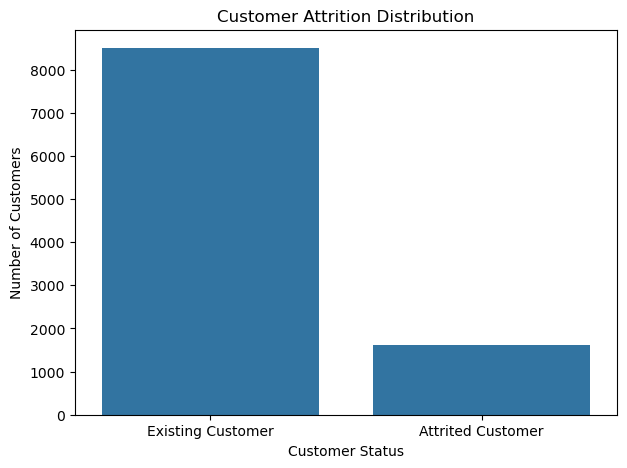

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='Attrition_Flag'
)

plt.title('Customer Attrition Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.show()

===========================================================================================================

## Data Preprocessing & Data Cleaning

===========================================================================================================

In [22]:
# Check the number of 'Unknown' values in each column

unknown_counts = (df == 'Unknown').sum()

unknown_summary = pd.DataFrame({
    'Unknown Values': unknown_counts,
    'Percentage': (unknown_counts / len(df) * 100).round(2)
})

unknown_summary[unknown_summary['Unknown Values'] > 0]

,Unknown Values,Percentage
Education_Level,1519,15.00
Marital_Status,749,7.40
Income_Category,1112,10.98


In [23]:
# Identify categorical columns

categorical_columns = df.select_dtypes(include='object').columns

print("Categorical Columns:")
print(categorical_columns.tolist())

Categorical Columns:
['Attrition_Flag', 'Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']


In [24]:
# Identify numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numerical_columns.tolist())

Numerical Columns:
['CLIENTNUM', 'Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']


In [25]:
# Display unique values for categorical columns

for column in categorical_columns:
    print("\n", "="*60)
    print(column)
    print(df[column].unique())


Attrition_Flag
['Existing Customer' 'Attrited Customer']

Gender
['M' 'F']

Education_Level
['High School' 'Graduate' 'Uneducated' 'Unknown' 'College' 'Post-Graduate'
 'Doctorate']

Marital_Status
['Married' 'Single' 'Unknown' 'Divorced']

Income_Category
['$60K - $80K' 'Less than $40K' '$80K - $120K' '$40K - $60K' '$120K +'
 'Unknown']

Card_Category
['Blue' 'Gold' 'Silver' 'Platinum']


Remove the Two Naive Bayes Columns

In [26]:
# Remove the two Naive Bayes classifier columns

naive_bayes_columns = [
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]

df = df.drop(columns=naive_bayes_columns)

print("Shape after removing Naive Bayes columns:", df.shape)

Shape after removing Naive Bayes columns: (10127, 21)


In [27]:
# Remove unique customer identifier

df = df.drop(columns=['CLIENTNUM'])

print("Shape after removing CLIENTNUM:", df.shape)

Shape after removing CLIENTNUM: (10127, 20)


In [28]:
# Verify the cleaned dataset

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 10127
Columns: 20


In [29]:
df.head()

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


In [30]:
# Check missing values after initial cleaning

print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [31]:
# Identify numerical columns

numerical_columns = df.select_dtypes(include=np.number).columns

# Calculate outliers using IQR

outlier_summary = []

for column in numerical_columns:
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]
    
    outlier_summary.append({
        'Feature': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier %': round(len(outliers) / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df    

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,Customer_Age,41.000,52.000,11.000,24.500,68.500,2,0.02
1,Dependent_count,1.000,3.000,2.000,-2.000,6.000,0,0.00
2,Months_on_book,31.000,40.000,9.000,17.500,53.500,386,3.81
3,Total_Relationship_Count,3.000,5.000,2.000,0.000,8.000,0,0.00
4,Months_Inactive_12_mon,2.000,3.000,1.000,0.500,4.500,331,3.27
5,Contacts_Count_12_mon,2.000,3.000,1.000,0.500,4.500,629,6.21
6,Credit_Limit,2555.000,11067.500,8512.500,-10213.750,23836.250,984,9.72
7,Total_Revolving_Bal,359.000,1784.000,1425.000,-1778.500,3921.500,0,0.00
8,Avg_Open_To_Buy,1324.500,9859.000,8534.500,-11477.250,22660.750,963,9.51
9,Total_Amt_Chng_Q4_Q1,0.631,0.859,0.228,0.289,1.201,396,3.91


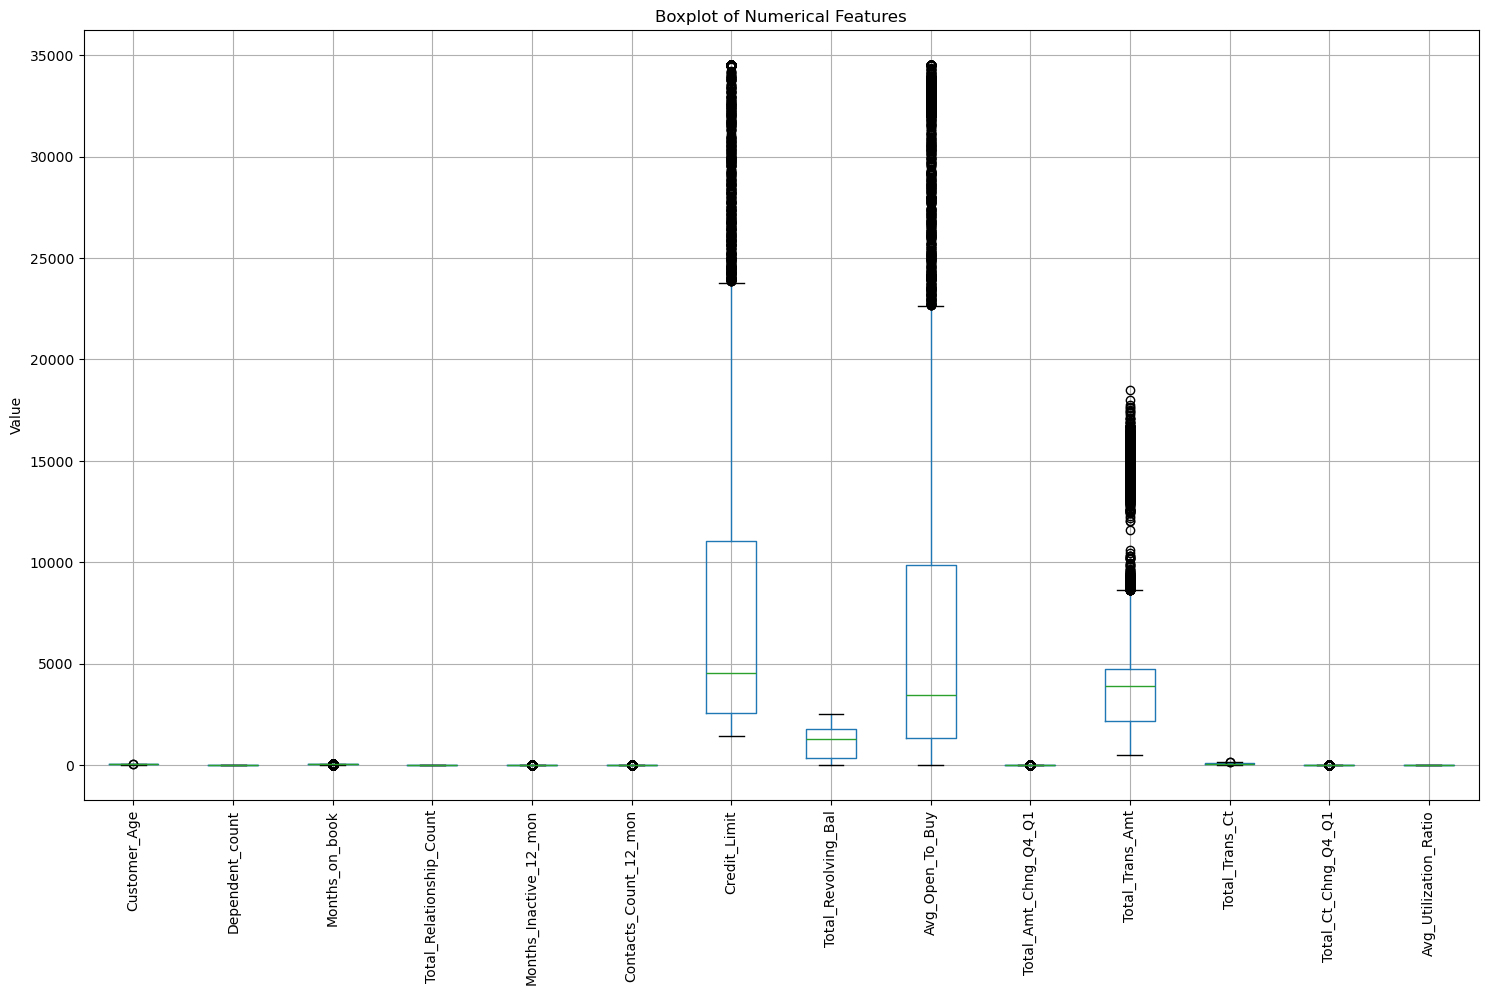

In [32]:
# Boxplots for numerical variables

plt.figure(figsize=(18, 10))

df[numerical_columns].boxplot()

plt.title("Boxplot of Numerical Features")
plt.xticks(rotation=90)
plt.ylabel("Value")

plt.show()

In [33]:
# Calculate skewness

skewness = df[numerical_columns].skew().sort_values(ascending=False)

skewness_df = pd.DataFrame({
    'Skewness': skewness
})

skewness_df

,Skewness
Total_Ct_Chng_Q4_Q1,2.064031
Total_Trans_Amt,2.041003
Total_Amt_Chng_Q4_Q1,1.732063
Credit_Limit,1.666726
Avg_Open_To_Buy,1.661697
Avg_Utilization_Ratio,0.718008
Months_Inactive_12_mon,0.633061
Total_Trans_Ct,0.153673
Contacts_Count_12_mon,0.011006
Dependent_count,-0.020826


In [34]:
# Identify highly skewed features

skewed_features = skewness_df[
    abs(skewness_df['Skewness']) > 1
]

skewed_features

,Skewness
Total_Ct_Chng_Q4_Q1,2.064031
Total_Trans_Amt,2.041003
Total_Amt_Chng_Q4_Q1,1.732063
Credit_Limit,1.666726
Avg_Open_To_Buy,1.661697


# ============================================================
# EXPLORATORY DATA ANALYSIS
# Prepare the cleaned dataset for EDA
# ============================================================

Exploratory Data Analysis

EDA is performed to understand the underlying patterns, distributions, relationships and characteristics of the credit-card customer dataset. Various statistical and graphical techniques are used to analyze customer demographics, financial characteristics, account activity and transaction behavior in relation to customer attrition.
The analysis includes univariate and bivariate analysis using histograms, boxplots, count plots, pie charts, bar plots, line plots, KDE plots, pair plots and correlation heatmaps.

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [36]:
df = pd.read_csv("C:\\Users\\silpa\\Downloads\\BankChurners.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [37]:
print("Original dataset shape:", df.shape)

Original dataset shape: (10127, 23)


In [38]:
# Reload the original dataset
df = pd.read_csv(r"C:\Users\silpa\Downloads\BankChurners.csv")

print("Original dataset shape:", df.shape)

# Remove the two Naive Bayes classifier columns
naive_bayes_columns = [
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
    'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'
]

df = df.drop(columns=naive_bayes_columns)

# Remove unique customer identifier
df = df.drop(columns=['CLIENTNUM'])

print("Cleaned dataset shape:", df.shape)

Original dataset shape: (10127, 23)
Cleaned dataset shape: (10127, 20)


In [39]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10127
Number of columns: 20


In [40]:
for i, column in enumerate(df.columns, start=1):
    print(i, ":", column)

1 : Attrition_Flag
2 : Customer_Age
3 : Gender
4 : Dependent_count
5 : Education_Level
6 : Marital_Status
7 : Income_Category
8 : Card_Category
9 : Months_on_book
10 : Total_Relationship_Count
11 : Months_Inactive_12_mon
12 : Contacts_Count_12_mon
13 : Credit_Limit
14 : Total_Revolving_Bal
15 : Avg_Open_To_Buy
16 : Total_Amt_Chng_Q4_Q1
17 : Total_Trans_Amt
18 : Total_Trans_Ct
19 : Total_Ct_Chng_Q4_Q1
20 : Avg_Utilization_Ratio


Customer Attrition
Count Plot

To understand the distribution of our target variable:

Attrition_Flag

It contains:
*Existing Customer
*Attrited Customer

In [41]:
# Verify the cleaned dataset

print("Dataset Shape:", df.shape)
print("Column Names:")
print(df.columns.tolist())

Dataset Shape: (10127, 20)
Column Names:
['Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']


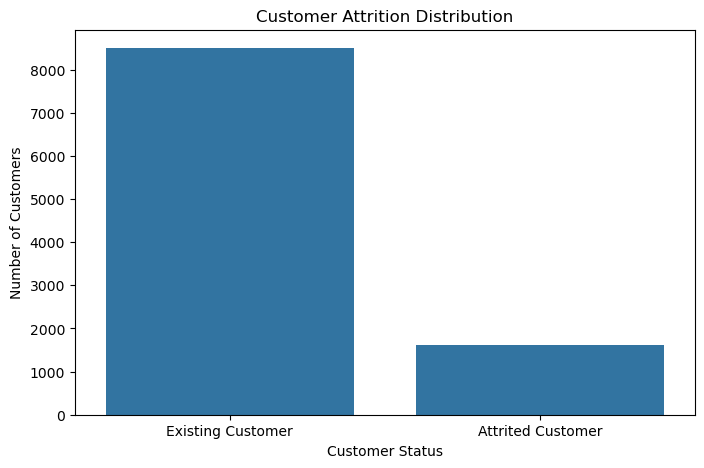

In [42]:
# Count Plot - Customer Attrition

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Attrition_Flag'
)

plt.title('Customer Attrition Distribution')
plt.xlabel('Customer Status')
plt.ylabel('Number of Customers')

plt.show()

Interpretation

The plot shows that Existing Customers are substantially more numerous than Attrited Customers, indicating that the target variable is imbalanced.

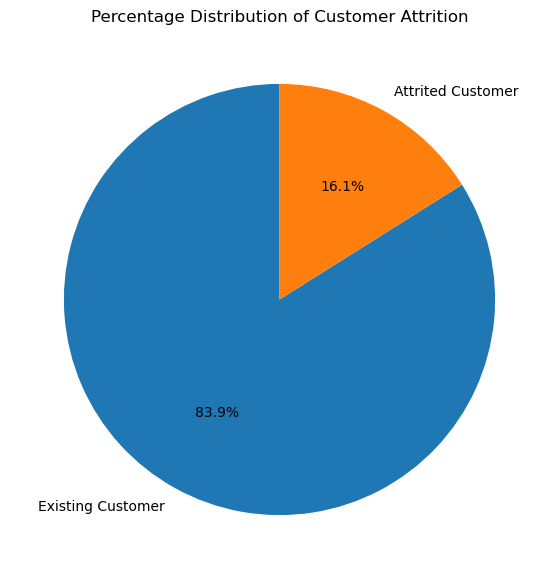

In [43]:
# Pie Chart - Customer Attrition

attrition_counts = df['Attrition_Flag'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    attrition_counts.values,
    labels=attrition_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Distribution of Customer Attrition')

plt.show()

Interpretation

The pie chart shows the percentage distribution of existing and attrited customers. Attrited customers represent a smaller proportion of the dataset.

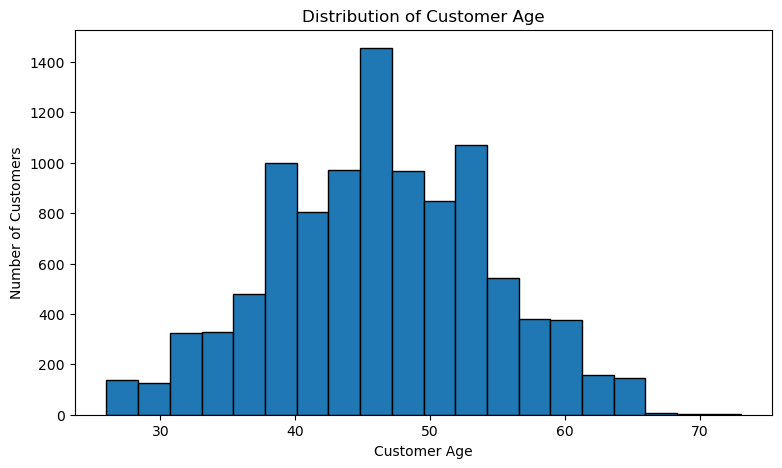

In [44]:
# Histogram - Customer Age

plt.figure(figsize=(9, 5))

plt.hist(
    df['Customer_Age'],
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of Customer Age')
plt.xlabel('Customer Age')
plt.ylabel('Number of Customers')

plt.show()

Interpretation

The histogram shows the distribution of customer ages and helps identify the age ranges that are most represented in the dataset.

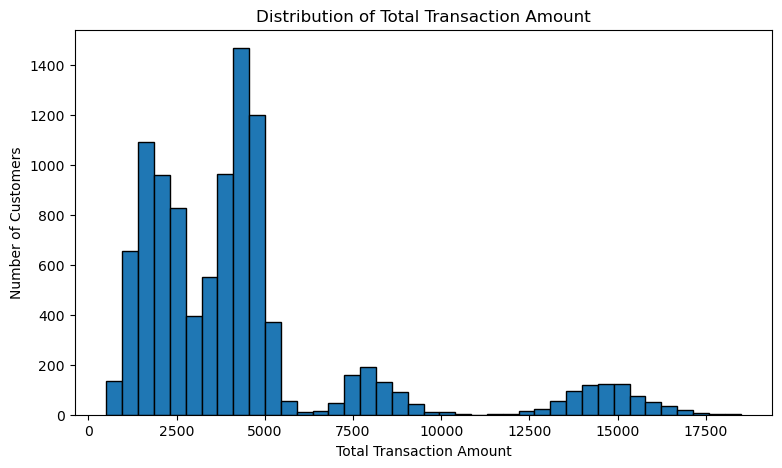

In [45]:
# Histogram - Total Transaction Amount

plt.figure(figsize=(9, 5))

plt.hist(
    df['Total_Trans_Amt'],
    bins=40,
    edgecolor='black'
)

plt.title('Distribution of Total Transaction Amount')
plt.xlabel('Total Transaction Amount')
plt.ylabel('Number of Customers')

plt.show()

Interpretation

The distribution is expected to be positively skewed, with a smaller number of customers having substantially higher transaction amounts.

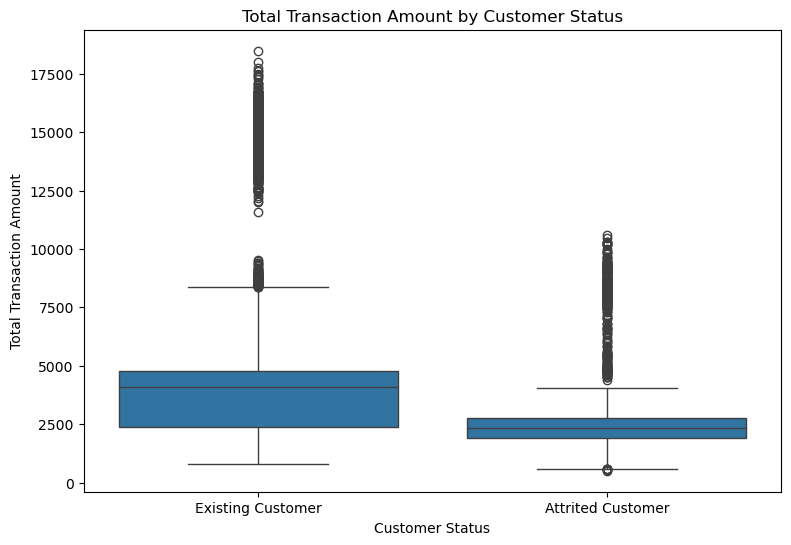

In [46]:
# Boxplot - Transaction Amount by Customer Status

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='Attrition_Flag',
    y='Total_Trans_Amt'
)

plt.title('Total Transaction Amount by Customer Status')
plt.xlabel('Customer Status')
plt.ylabel('Total Transaction Amount')

plt.show()

Interpretation

This boxplot compares transaction amounts between existing and attrited customers and also helps visualize the spread and potential extreme values.

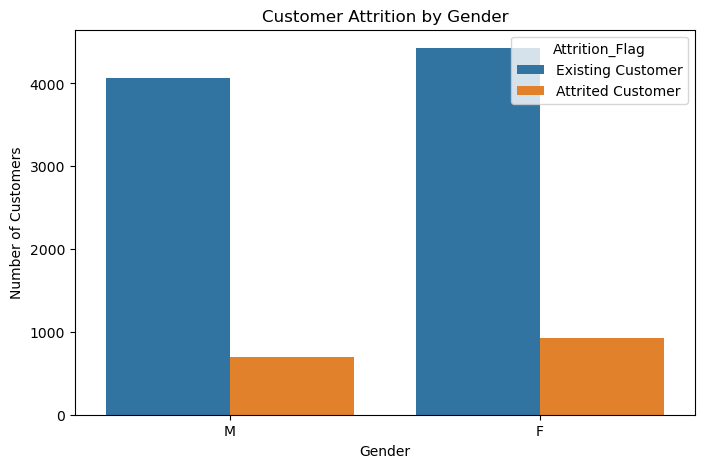

In [47]:
# Count Plot - Gender vs Customer Attrition

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Gender',
    hue='Attrition_Flag'
)

plt.title('Customer Attrition by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

Interpretation

This plot compares the number of existing and attrited customers across gender categories.

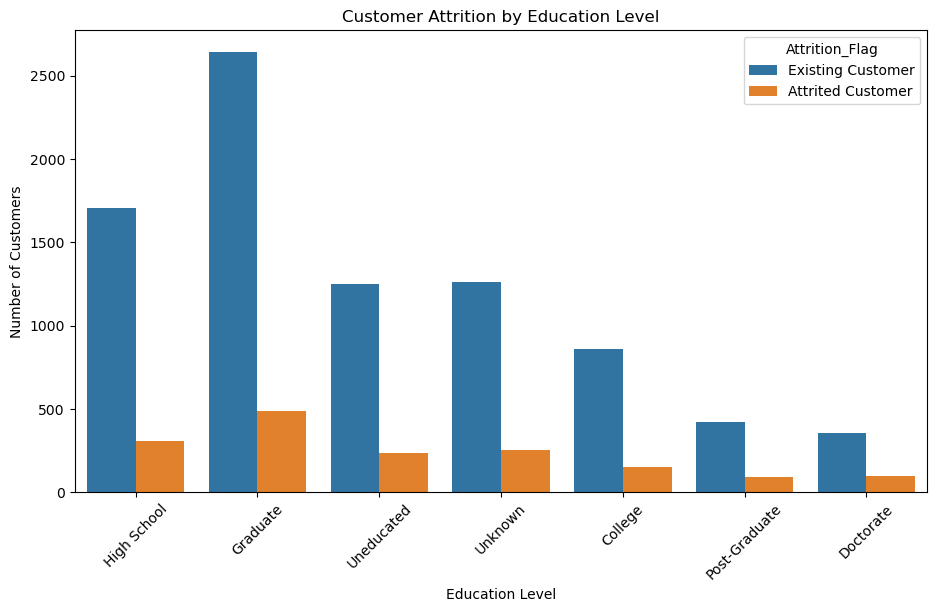

In [48]:
# Count Plot - Education Level vs Customer Attrition

plt.figure(figsize=(11, 6))

sns.countplot(
    data=df,
    x='Education_Level',
    hue='Attrition_Flag'
)

plt.title('Customer Attrition by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)

plt.show()

In [49]:
# Calculate attrition rate by income category

income_attrition = pd.crosstab(
    df['Income_Category'],
    df['Attrition_Flag'],
    normalize='index'
) * 100

# Display the calculated percentages

print(income_attrition.round(2))

Attrition_Flag   Attrited Customer  Existing Customer
Income_Category                                      
$120K +                      17.33              82.67
$40K - $60K                  15.14              84.86
$60K - $80K                  13.48              86.52
$80K - $120K                 15.77              84.23
Less than $40K               17.19              82.81
Unknown                      16.82              83.18


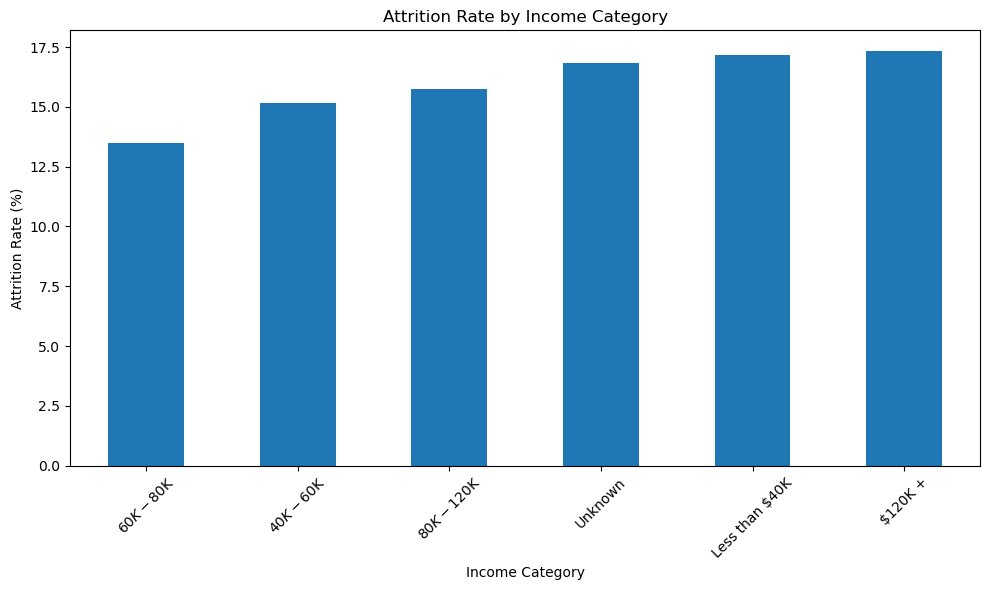

In [50]:
# Bar Plot - Attrition Rate by Income Category

plt.figure(figsize=(10, 6))

income_attrition['Attrited Customer'].sort_values().plot(
    kind='bar'
)

plt.title('Attrition Rate by Income Category')
plt.xlabel('Income Category')
plt.ylabel('Attrition Rate (%)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Interpretation

This chart compares the percentage of attrited customers within each income category and helps identify whether attrition varies across income groups.

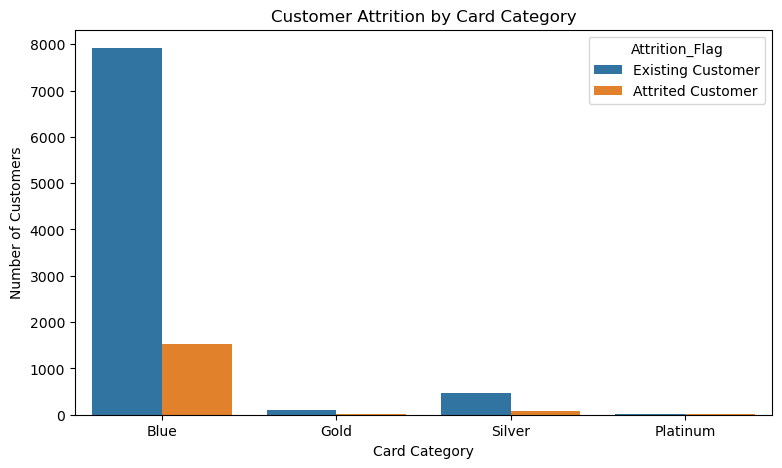

In [51]:
# Count Plot - Card Category vs Customer Attrition

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Card_Category',
    hue='Attrition_Flag'
)

plt.title('Customer Attrition by Card Category')
plt.xlabel('Card Category')
plt.ylabel('Number of Customers')

plt.show()

In [52]:
# Calculate average transaction amount by customer status

average_transaction = df.groupby(
    'Attrition_Flag'
)['Total_Trans_Amt'].mean()

print(average_transaction)

Attrition_Flag
Attrited Customer    3095.025814
Existing Customer    4654.655882
Name: Total_Trans_Amt, dtype: float64


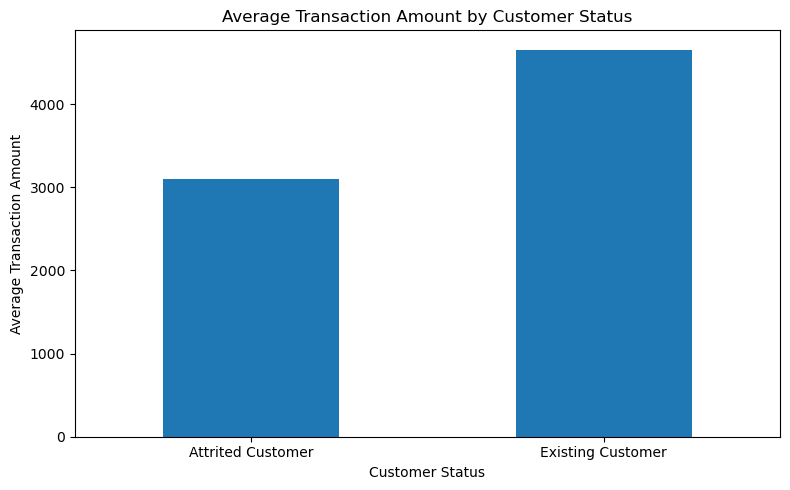

In [53]:
# Bar Plot - Average Transaction Amount by Customer Status

plt.figure(figsize=(8, 5))

average_transaction.plot(kind='bar')

plt.title('Average Transaction Amount by Customer Status')
plt.xlabel('Customer Status')
plt.ylabel('Average Transaction Amount')

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [54]:
# Calculate attrition rate by age

age_attrition = (
    df.groupby('Customer_Age')['Attrition_Flag']
    .apply(lambda x: (x == 'Attrited Customer').mean() * 100)
)

print(age_attrition.head())

Customer_Age
26     7.692308
27     9.375000
28     3.448276
29    12.500000
30    21.428571
Name: Attrition_Flag, dtype: float64


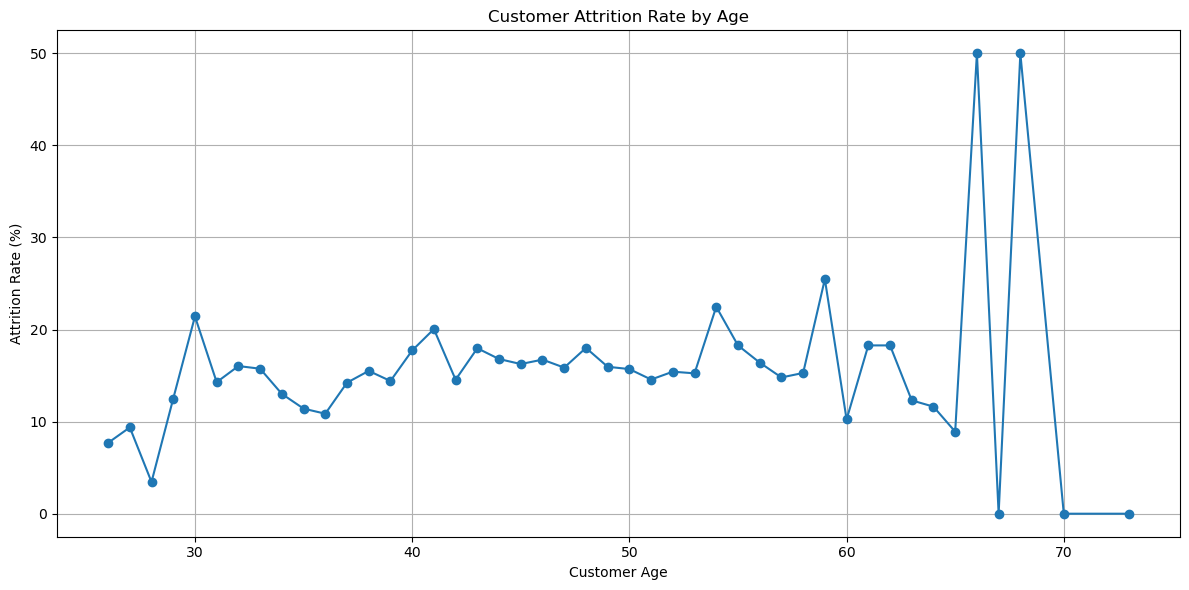

In [55]:
# Line Plot - Attrition Rate by Age

plt.figure(figsize=(12, 6))

plt.plot(
    age_attrition.index,
    age_attrition.values,
    marker='o'
)

plt.title('Customer Attrition Rate by Age')
plt.xlabel('Customer Age')
plt.ylabel('Attrition Rate (%)')

plt.grid(True)

plt.tight_layout()
plt.show()

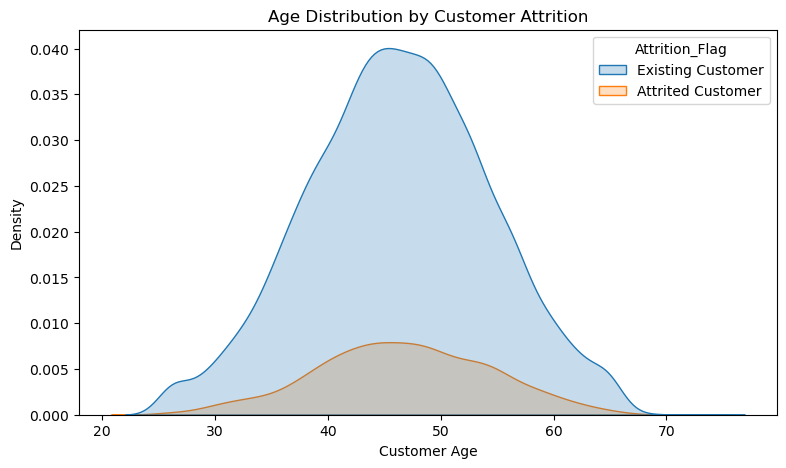

In [56]:
# KDE Plot - Age Distribution by Customer Status

plt.figure(figsize=(9, 5))

sns.kdeplot(
    data=df,
    x='Customer_Age',
    hue='Attrition_Flag',
    fill=True
)

plt.title('Age Distribution by Customer Attrition')
plt.xlabel('Customer Age')
plt.ylabel('Density')

plt.show()

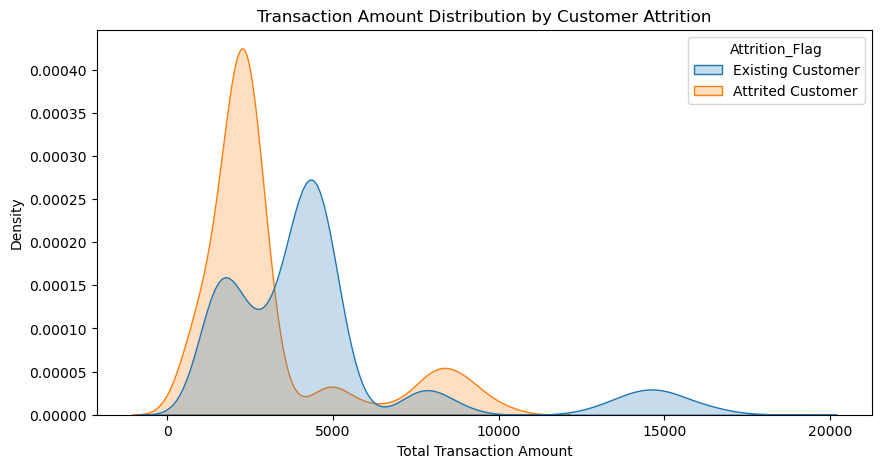

In [57]:
# KDE Plot - Transaction Amount by Customer Status

plt.figure(figsize=(10, 5))

sns.kdeplot(
    data=df,
    x='Total_Trans_Amt',
    hue='Attrition_Flag',
    fill=True,
    common_norm=False
)

plt.title('Transaction Amount Distribution by Customer Attrition')
plt.xlabel('Total Transaction Amount')
plt.ylabel('Density')

plt.show()

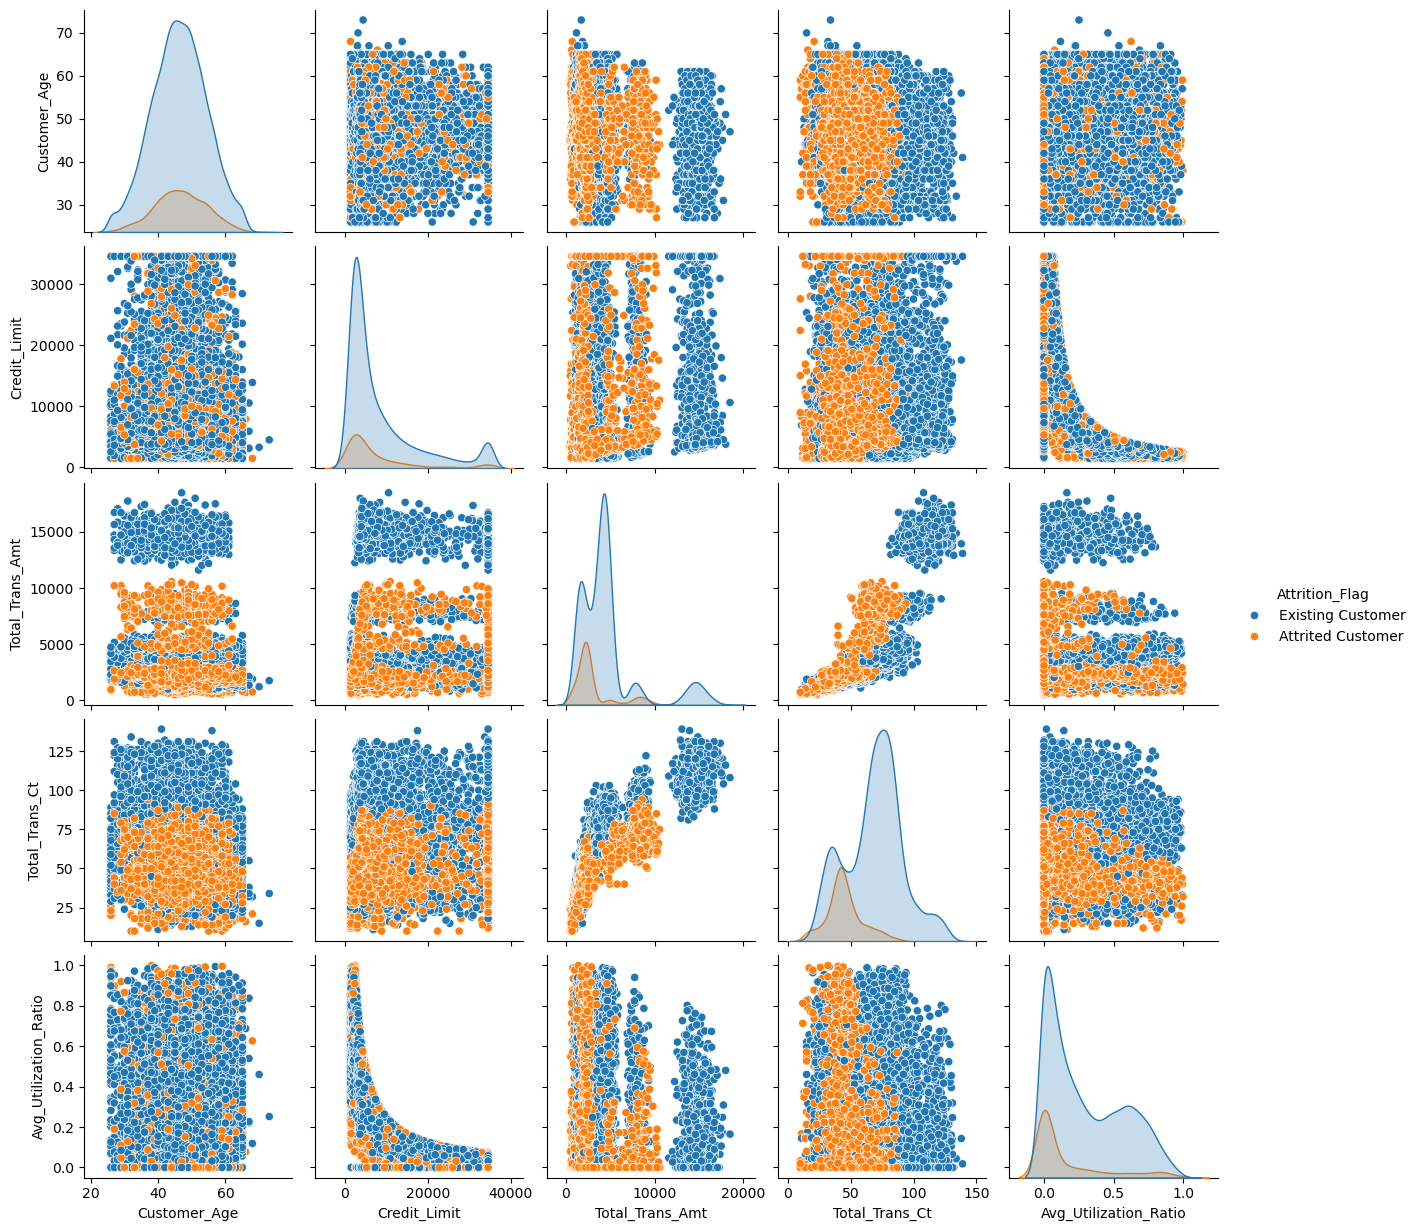

In [58]:
# Selected features for Pair Plot

pairplot_features = [
    'Customer_Age',
    'Credit_Limit',
    'Total_Trans_Amt',
    'Total_Trans_Ct',
    'Avg_Utilization_Ratio',
    'Attrition_Flag'
]

sns.pairplot(
    df[pairplot_features],
    hue='Attrition_Flag',
    diag_kind='kde'
)

plt.show()

Interpretation

The pair plot helps visualize relationships between selected numerical variables and shows whether the patterns differ between existing and attrited customers.

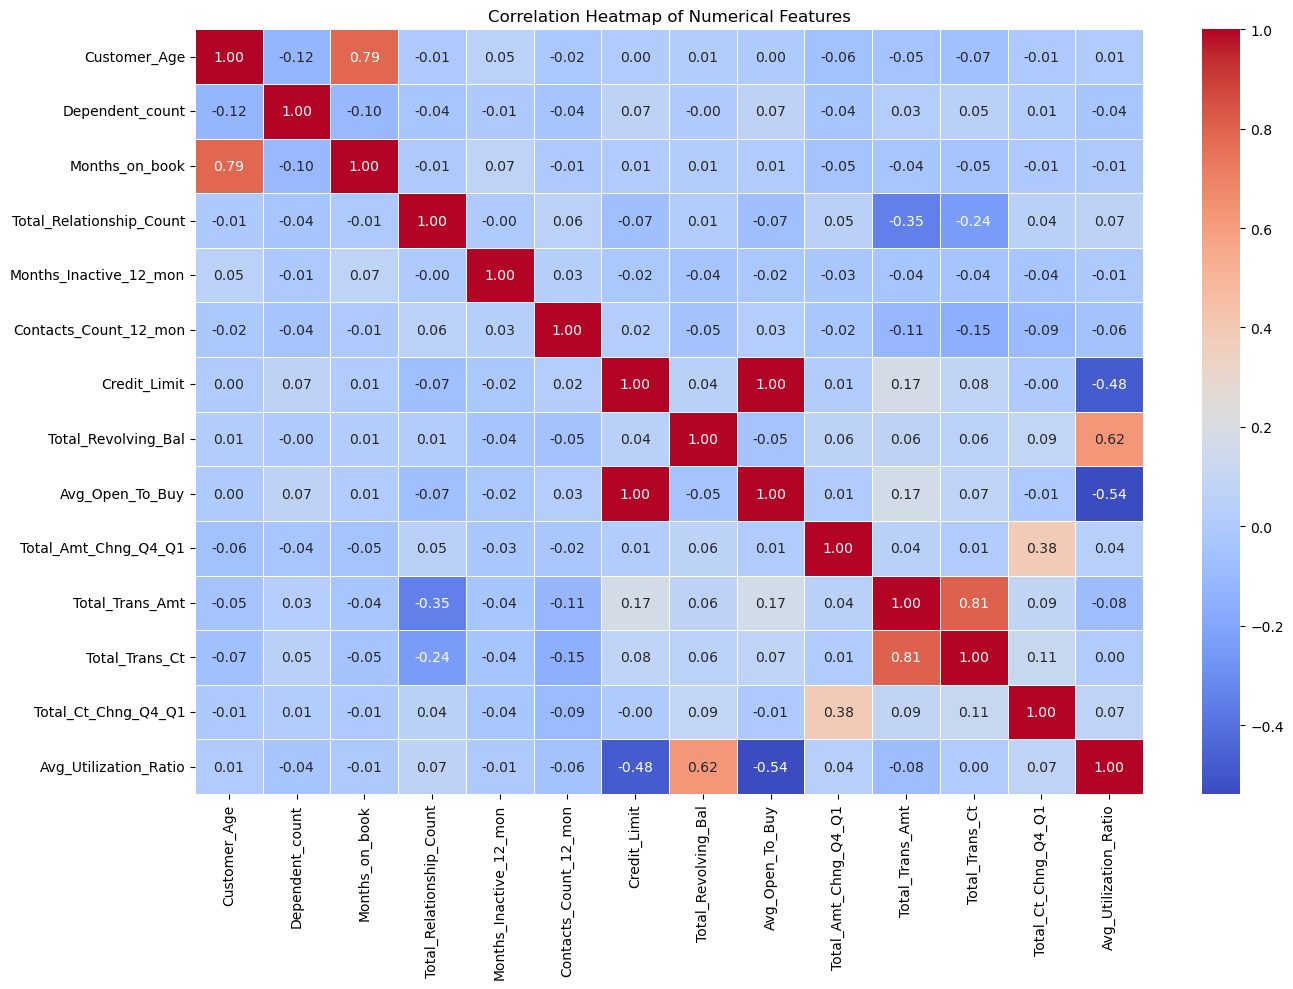

In [59]:
# Select numerical columns

numeric_df = df.select_dtypes(include=np.number)

# Calculate correlation matrix

correlation_matrix = numeric_df.corr()

# Plot correlation heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')

plt.tight_layout()
plt.show()

Interpretation

The correlation heatmap helps identify the strength and direction of relationships among numerical features. Highly correlated variables will be examined later during feature selection.

In [60]:
# Temporary binary encoding of target for correlation analysis

df['Attrition_Flag_Binary'] = df['Attrition_Flag'].map({
    'Existing Customer': 0,
    'Attrited Customer': 1
})

In [61]:
# Calculate correlation with customer attrition

target_correlation = (
    df.select_dtypes(include=np.number)
    .corr()['Attrition_Flag_Binary']
    .sort_values(ascending=False)
)

print(target_correlation)

Attrition_Flag_Binary       1.000000
Contacts_Count_12_mon       0.204491
Months_Inactive_12_mon      0.152449
Dependent_count             0.018991
Customer_Age                0.018203
Months_on_book              0.013687
Avg_Open_To_Buy            -0.000285
Credit_Limit               -0.023873
Total_Amt_Chng_Q4_Q1       -0.131063
Total_Relationship_Count   -0.150005
Total_Trans_Amt            -0.168598
Avg_Utilization_Ratio      -0.178410
Total_Revolving_Bal        -0.263053
Total_Ct_Chng_Q4_Q1        -0.290054
Total_Trans_Ct             -0.371403
Name: Attrition_Flag_Binary, dtype: float64


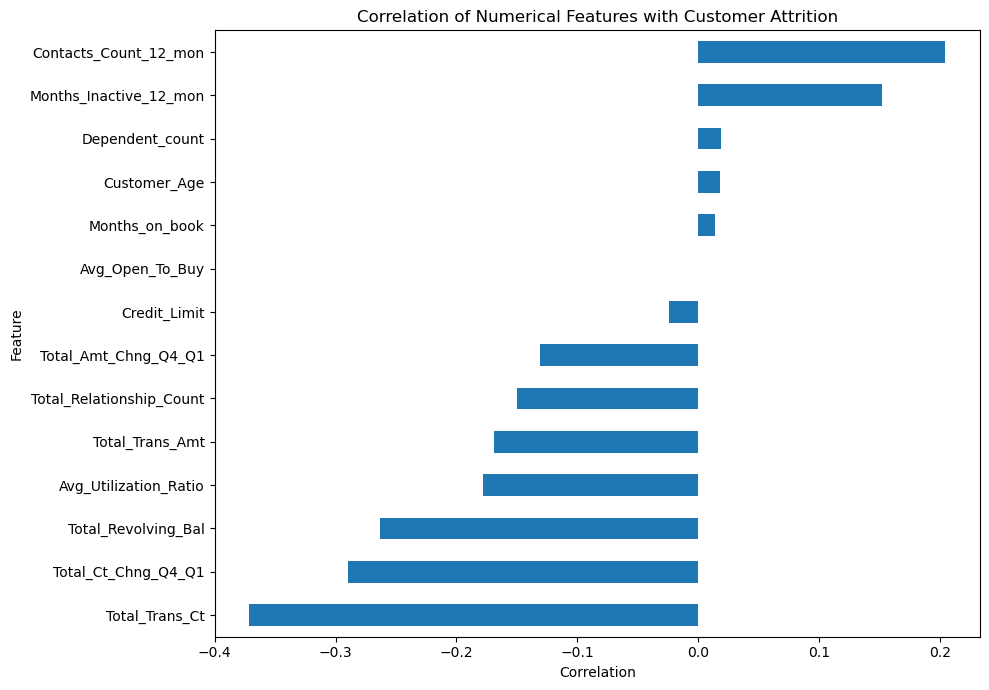

In [62]:
# Plot correlation with customer attrition

plt.figure(figsize=(10, 7))

target_correlation.drop(
    'Attrition_Flag_Binary'
).sort_values().plot(
    kind='barh'
)

plt.title('Correlation of Numerical Features with Customer Attrition')
plt.xlabel('Correlation')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [63]:
# Remove temporary target column

df.drop(
    columns=['Attrition_Flag_Binary'],
    inplace=True
)

print("Temporary column removed.")
print("Current dataset shape:", df.shape)

Temporary column removed.
Current dataset shape: (10127, 20)


In [64]:
# Temporary binary encoding of target

df['Attrition_Flag_Binary'] = df['Attrition_Flag'].map({
    'Existing Customer': 0,
    'Attrited Customer': 1
})

# Calculate correlations

target_correlation = (
    df.select_dtypes(include=np.number)
    .corr()['Attrition_Flag_Binary']
    .sort_values(ascending=False)
)

print(target_correlation)

Attrition_Flag_Binary       1.000000
Contacts_Count_12_mon       0.204491
Months_Inactive_12_mon      0.152449
Dependent_count             0.018991
Customer_Age                0.018203
Months_on_book              0.013687
Avg_Open_To_Buy            -0.000285
Credit_Limit               -0.023873
Total_Amt_Chng_Q4_Q1       -0.131063
Total_Relationship_Count   -0.150005
Total_Trans_Amt            -0.168598
Avg_Utilization_Ratio      -0.178410
Total_Revolving_Bal        -0.263053
Total_Ct_Chng_Q4_Q1        -0.290054
Total_Trans_Ct             -0.371403
Name: Attrition_Flag_Binary, dtype: float64


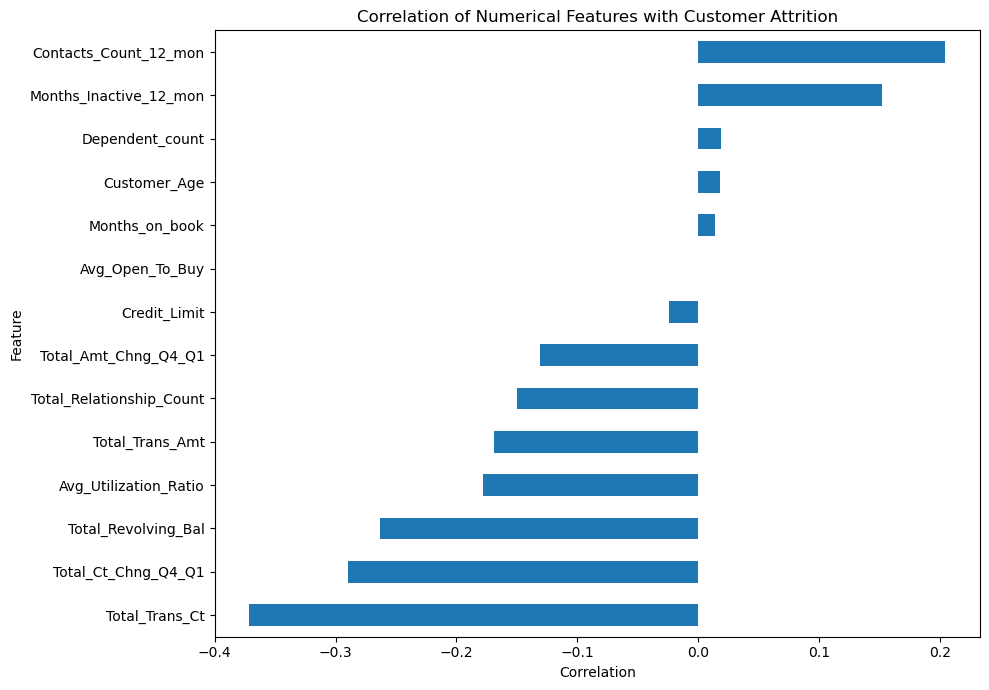

In [65]:
plt.figure(figsize=(10, 7))

target_correlation.drop(
    'Attrition_Flag_Binary'
).sort_values().plot(
    kind='barh'
)

plt.title('Correlation of Numerical Features with Customer Attrition')
plt.xlabel('Correlation')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [66]:
df.drop(
    columns=['Attrition_Flag_Binary'],
    inplace=True
)

print("Temporary target column removed.")
print("Final EDA dataset shape:", df.shape)

Temporary target column removed.
Final EDA dataset shape: (10127, 20)


In [67]:
%pip install -U scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [68]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [69]:
import sys

print("Python version:", sys.version)

Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [70]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)
print("Scikit-learn location:", sklearn.__file__)

Scikit-learn version: 1.9.1
Scikit-learn location: c:\Users\silpa\Downloads\Anaconda\Lib\site-packages\sklearn\__init__.py


===========================================================================================================

## FEATURE ENGINEERING

===========================================================================================================

Feature engineering is performed to convert the raw customer information into a format suitable for machine learning algorithms. The dataset contains both numerical and categorical variables. The categorical variables are encoded using One-Hot Encoding, while numerical variables are standardized using StandardScaler. The target variable Attrition_Flag is converted into binary form, where Existing Customer is represented by 0 and Attrited Customer by 1.
The categorical value Unknown is retained as a separate category because it represents an unknown category in the original dataset rather than an explicit missing value.

In [71]:
# Check current dataset

print("Dataset Shape:", df.shape)

print("Columns:")
print(df.columns.tolist())

Dataset Shape: (10127, 20)
Columns:
['Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']


In [72]:
# Convert target variable into binary format

df['Attrition_Flag'] = df['Attrition_Flag'].map({
    'Existing Customer': 0,
    'Attrited Customer': 1
})

print(df['Attrition_Flag'].value_counts())

Attrition_Flag
0    8500
1    1627
Name: count, dtype: int64


In [73]:
# Target distribution after encoding

print(
    df['Attrition_Flag']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Attrition_Flag
0    83.93
1    16.07
Name: proportion, dtype: float64


In [74]:
# Separate independent variables and target variable

X = df.drop(columns=['Attrition_Flag'])
y = df['Attrition_Flag']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10127, 19)
Target shape: (10127,)


In [75]:
# Identify numerical features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nNumber of Numerical Features:", len(numerical_features))

Numerical Features:
['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']

Number of Numerical Features: 14


In [76]:
# Identify categorical features

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("Number of Categorical Features:", len(categorical_features))

Categorical Features:
['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']
Number of Categorical Features: 5


In [77]:
# Feature type summary

feature_summary = pd.DataFrame({
    'Feature': X.columns,
    'Data Type': X.dtypes.astype(str).values,
    'Category': [
        'Numerical' if column in numerical_features else 'Categorical'
        for column in X.columns
    ]
})

feature_summary

,Feature,Data Type,Category
0,Customer_Age,int64,Numerical
1,Gender,object,Categorical
2,Dependent_count,int64,Numerical
3,Education_Level,object,Categorical
4,Marital_Status,object,Categorical
5,Income_Category,object,Categorical
6,Card_Category,object,Categorical
7,Months_on_book,int64,Numerical
8,Total_Relationship_Count,int64,Numerical
9,Months_Inactive_12_mon,int64,Numerical


In [78]:
# Check Unknown values in categorical features

for column in categorical_features:
    print(f"{column}")
    print(X[column].value_counts())

Gender
Gender
F    5358
M    4769
Name: count, dtype: int64
Education_Level
Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64
Marital_Status
Marital_Status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64
Income_Category
Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64
Card_Category
Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64


In [79]:
# Convert target variable into binary format
df['Attrition_Flag'] = df['Attrition_Flag'].map({
    'Existing Customer': 0,
    'Attrited Customer': 1
})

# Separate independent variables and target variable
X = df.drop(columns=['Attrition_Flag'])
y = df['Attrition_Flag']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Identify numerical and categorical features
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Features shape: (10127, 19)
Target shape: (10127,)
Numerical Features: ['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
Categorical Features: ['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']


In [80]:
print("Attrition_Flag values:")
print(df['Attrition_Flag'].value_counts(dropna=False))

print("Data type:")
print(df['Attrition_Flag'].dtype)

print("Number of NaN values:")
print(df['Attrition_Flag'].isna().sum())

Attrition_Flag values:
Attrition_Flag
NaN    10127
Name: count, dtype: int64
Data type:
float64
Number of NaN values:
10127


In [81]:
# Reload the original dataset
df = pd.read_csv(r"C:\Users\silpa\Downloads\BankChurners.csv")

# Remove CLIENTNUM
if 'CLIENTNUM' in df.columns:
    df = df.drop(columns=['CLIENTNUM'])

# Remove ALL Naive Bayes classifier columns
naive_bayes_columns = [
    col for col in df.columns
    if col.startswith('Naive_Bayes_Classifier')
]

print("Naive Bayes columns found:")
print(naive_bayes_columns)

df = df.drop(columns=naive_bayes_columns)

print("Dataset shape after cleaning:", df.shape)
print("Remaining columns:")
print(df.columns.tolist())

Naive Bayes columns found:
['Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1', 'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2']
Dataset shape after cleaning: (10127, 20)
Remaining columns:
['Attrition_Flag', 'Customer_Age', 'Gender', 'Dependent_count', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']


In [82]:
print("Target distribution:")
print(df['Attrition_Flag'].value_counts())

print("Missing target values:")
print(df['Attrition_Flag'].isna().sum())

Target distribution:
Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64
Missing target values:
0


In [83]:
# Encode the target variable

df['Attrition_Flag'] = df['Attrition_Flag'].map({
    'Existing Customer': 0,
    'Attrited Customer': 1
})

print(df['Attrition_Flag'].value_counts())
print("Missing values:", df['Attrition_Flag'].isna().sum())

Attrition_Flag
0    8500
1    1627
Name: count, dtype: int64
Missing values: 0


In [84]:
# Separate features and target

X = df.drop(columns=['Attrition_Flag'])
y = df['Attrition_Flag']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10127, 19)
y shape: (10127,)


In [85]:
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("Number of numerical features:",
      len(numerical_features))

Numerical features:
['Customer_Age', 'Dependent_count', 'Months_on_book', 'Total_Relationship_Count', 'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal', 'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt', 'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio']
Number of numerical features: 14


In [86]:
categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("Number of categorical features:",
      len(categorical_features))

Categorical features:
['Gender', 'Education_Level', 'Marital_Status', 'Income_Category', 'Card_Category']
Number of categorical features: 5


In [87]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (8101, 19)
Testing feature shape: (2026, 19)

Training target shape: (8101,)
Testing target shape: (2026,)


In [88]:
# Check target distribution in training and testing data

print("Training target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("Testing target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training target distribution:
Attrition_Flag
0    83.93
1    16.07
Name: proportion, dtype: float64
Testing target distribution:
Attrition_Flag
0    83.96
1    16.04
Name: proportion, dtype: float64


In [89]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [90]:
# Numerical preprocessing

numerical_transformer = StandardScaler()

In [91]:
# Categorical preprocessing

categorical_transformer = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

In [92]:
# Combine numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [93]:
# Fit the preprocessor on training data only

X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the already-fitted preprocessor

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (8101, 37)
Testing data after preprocessing: (2026, 37)


In [94]:
# Get feature names after encoding

feature_names = preprocessor.get_feature_names_out()

print("Number of features after encoding:", len(feature_names))

print("First 20 transformed features:")
print(feature_names[:20])

Number of features after encoding: 37
First 20 transformed features:
['num__Customer_Age' 'num__Dependent_count' 'num__Months_on_book'
 'num__Total_Relationship_Count' 'num__Months_Inactive_12_mon'
 'num__Contacts_Count_12_mon' 'num__Credit_Limit'
 'num__Total_Revolving_Bal' 'num__Avg_Open_To_Buy'
 'num__Total_Amt_Chng_Q4_Q1' 'num__Total_Trans_Amt' 'num__Total_Trans_Ct'
 'num__Total_Ct_Chng_Q4_Q1' 'num__Avg_Utilization_Ratio' 'cat__Gender_F'
 'cat__Gender_M' 'cat__Education_Level_College'
 'cat__Education_Level_Doctorate' 'cat__Education_Level_Graduate'
 'cat__Education_Level_High School']


In [95]:
# Convert processed training data into DataFrame

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed training data:")
display(X_train_processed_df.head())

Processed training data:


,num__Customer_Age,num__Dependent_count,num__Months_on_book,num__Total_Relationship_Count,num__Months_Inactive_12_mon,num__Contacts_Count_12_mon,num__Credit_Limit,num__Total_Revolving_Bal,num__Avg_Open_To_Buy,num__Total_Amt_Chng_Q4_Q1,num__Total_Trans_Amt,num__Total_Trans_Ct,num__Total_Ct_Chng_Q4_Q1,num__Avg_Utilization_Ratio,cat__Gender_F,cat__Gender_M,cat__Education_Level_College,cat__Education_Level_Doctorate,cat__Education_Level_Graduate,cat__Education_Level_High School,cat__Education_Level_Post-Graduate,cat__Education_Level_Uneducated,cat__Education_Level_Unknown,cat__Marital_Status_Divorced,cat__Marital_Status_Married,cat__Marital_Status_Single,cat__Marital_Status_Unknown,cat__Income_Category_$120K +,cat__Income_Category_$40K - $60K,cat__Income_Category_$60K - $80K,cat__Income_Category_$80K - $120K,cat__Income_Category_Less than $40K,cat__Income_Category_Unknown,cat__Card_Category_Blue,cat__Card_Category_Gold,cat__Card_Category_Platinum,cat__Card_Category_Silver
2856,-1.301232,-1.809900,-1.513205,0.122196,0.646495,-0.411236,-0.665434,1.303942,-0.783057,-0.335597,-0.775093,-0.961644,-1.093573,2.148867,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
6515,-0.299340,0.501503,-0.000700,0.765411,-0.342413,0.489635,1.848571,-1.433246,1.977862,0.407489,-0.619960,-1.131083,-0.537244,-1.000072,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
7141,-0.048867,-0.268965,-0.756952,1.408625,0.646495,-1.312106,0.342117,-0.310139,0.370094,0.603518,-0.032694,1.029259,0.579534,-0.717103,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
632,-1.301232,-0.268965,-1.513205,-0.521019,-1.331320,0.489635,-0.604095,0.522064,-0.651190,0.498665,-0.805413,-1.004004,-1.427370,0.850111,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3496,0.452079,-1.039432,0.503468,0.122196,-0.342413,0.489635,2.871622,0.021269,2.869713,-0.157803,-0.151325,0.309145,0.002601,-0.876727,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [96]:
# Check descriptive statistics of processed numerical features

X_train_processed_df.describe().T.head(10)

,count,mean,std,min,25%,50%,75%,max
num__Customer_Age,8101.0,-3.297915e-16,1.000062,-2.553597,-0.675050,-0.048867,0.702552,3.332519
num__Dependent_count,8101.0,7.016840e-17,1.000062,-1.809900,-1.039432,-0.268965,0.501503,2.042438
num__Months_on_book,8101.0,1.245489e-16,1.000062,-2.899667,-0.504868,-0.000700,0.503468,2.520141
num__Total_Relationship_Count,8101.0,1.442838e-16,1.000062,-1.807449,-0.521019,0.122196,0.765411,1.408625
num__Months_Inactive_12_mon,8101.0,1.377055e-16,1.000062,-2.320227,-0.342413,-0.342413,0.646495,3.613217
num__Contacts_Count_12_mon,8101.0,4.473235e-17,1.000062,-2.212977,-0.411236,-0.411236,0.489635,3.192247
num__Credit_Limit,8101.0,8.464063e-17,1.000062,-0.790736,-0.666320,-0.448202,0.264945,2.871622
num__Total_Revolving_Bal,8101.0,2.543604e-17,1.000062,-1.433246,-0.928768,0.148922,0.758959,1.656217
num__Avg_Open_To_Buy,8101.0,-1.578789e-17,1.000062,-0.819595,-0.673555,-0.438275,0.258820,3.000917
num__Total_Amt_Chng_Q4_Q1,8101.0,-4.648656e-17,1.000062,-3.462938,-0.590890,-0.112215,0.453077,12.023330


In [97]:
print("Final Training Data Shape:", X_train_processed_df.shape)
print("Final Testing Data Shape:", X_test_processed_df.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Final Training Data Shape: (8101, 37)
Final Testing Data Shape: (2026, 37)
Training Target Shape: (8101,)
Testing Target Shape: (2026,)


In [98]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical feature transformer
numerical_transformer = StandardScaler()

# Categorical feature transformer
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [99]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (8101, 37)
Testing processed shape: (2026, 37)


In [100]:
# Get the names of the processed features
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))
print("Processed feature names:")
print(feature_names)

Number of processed features: 37
Processed feature names:
['num__Customer_Age' 'num__Dependent_count' 'num__Months_on_book'
 'num__Total_Relationship_Count' 'num__Months_Inactive_12_mon'
 'num__Contacts_Count_12_mon' 'num__Credit_Limit'
 'num__Total_Revolving_Bal' 'num__Avg_Open_To_Buy'
 'num__Total_Amt_Chng_Q4_Q1' 'num__Total_Trans_Amt' 'num__Total_Trans_Ct'
 'num__Total_Ct_Chng_Q4_Q1' 'num__Avg_Utilization_Ratio' 'cat__Gender_F'
 'cat__Gender_M' 'cat__Education_Level_College'
 'cat__Education_Level_Doctorate' 'cat__Education_Level_Graduate'
 'cat__Education_Level_High School' 'cat__Education_Level_Post-Graduate'
 'cat__Education_Level_Uneducated' 'cat__Education_Level_Unknown'
 'cat__Marital_Status_Divorced' 'cat__Marital_Status_Married'
 'cat__Marital_Status_Single' 'cat__Marital_Status_Unknown'
 'cat__Income_Category_$120K +' 'cat__Income_Category_$40K - $60K'
 'cat__Income_Category_$60K - $80K' 'cat__Income_Category_$80K - $120K'
 'cat__Income_Category_Less than $40K' 'cat__Income

In [101]:
# Convert processed arrays into DataFrames

X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Training processed DataFrame:",
      X_train_processed_df.shape)

print("Testing processed DataFrame:",
      X_test_processed_df.shape)

Training processed DataFrame: (8101, 37)
Testing processed DataFrame: (2026, 37)


### Feature Engineering Summary


The target variable "Attrition_Flag" was converted into binary format, where 0 represents an Existing Customer and 1 represents an Attrited Customer. The predictor variables were divided into numerical and categorical features.


The categorical variables were encoded using One-Hot Encoding, while numerical variables were standardized using StandardScaler. The "Unknown" categories present in the original dataset were retained as separate categorical levels.


The dataset was divided into training and testing sets using an 80:20 ratio with stratified sampling to preserve the class distribution. The preprocessing transformations were fitted only on the training data and subsequently applied to the testing data to reduce the risk of data leakage.


A ColumnTransformer was used to combine the numerical and categorical preprocessing steps.

===========================================================================================================

## FEATURE SELECTION

===========================================================================================================

Feature selection is used to identify the most relevant features for predicting customer churn.

In this project, two approaches are used:

1. SelectKBest using the ANOVA F-test (f_classif)
2. Random Forest feature importance


The purpose is to identify important features, reduce unnecessary features, and improve model efficiency while retaining useful predictive information.

In [102]:
print("Training data shape:", X_train_processed_df.shape)
print("Testing data shape:", X_test_processed_df.shape)

print("Number of features:", len(feature_names))

Training data shape: (8101, 37)
Testing data shape: (2026, 37)
Number of features: 37


In [103]:
from sklearn.feature_selection import SelectKBest, f_classif

# Calculate SelectKBest scores for all features
select_kbest = SelectKBest(score_func=f_classif, k='all')

select_kbest.fit(X_train_processed_df, y_train)

# Create feature score table
kbest_scores = pd.DataFrame({
    'Feature': feature_names,
    'F_Score': select_kbest.scores_,
    'P_Value': select_kbest.pvalues_
})

# Sort by F-score
kbest_scores = kbest_scores.sort_values(
    by='F_Score',
    ascending=False
)

kbest_scores.head(20)

,Feature,F_Score,P_Value
11,num__Total_Trans_Ct,1304.840615,4.672547e-265
12,num__Total_Ct_Chng_Q4_Q1,724.081801,7.826216e-153
7,num__Total_Revolving_Bal,624.638229,7.200815e-133
5,num__Contacts_Count_12_mon,357.053749,5.766715e-78
13,num__Avg_Utilization_Ratio,298.439252,1.074262e-65
10,num__Total_Trans_Amt,251.300721,9.267982e-56
4,num__Months_Inactive_12_mon,207.190324,2.099911e-46
3,num__Total_Relationship_Count,204.922922,6.377533e-46
9,num__Total_Amt_Chng_Q4_Q1,137.395987,1.772444e-31
15,cat__Gender_M,14.317816,1.555099e-04


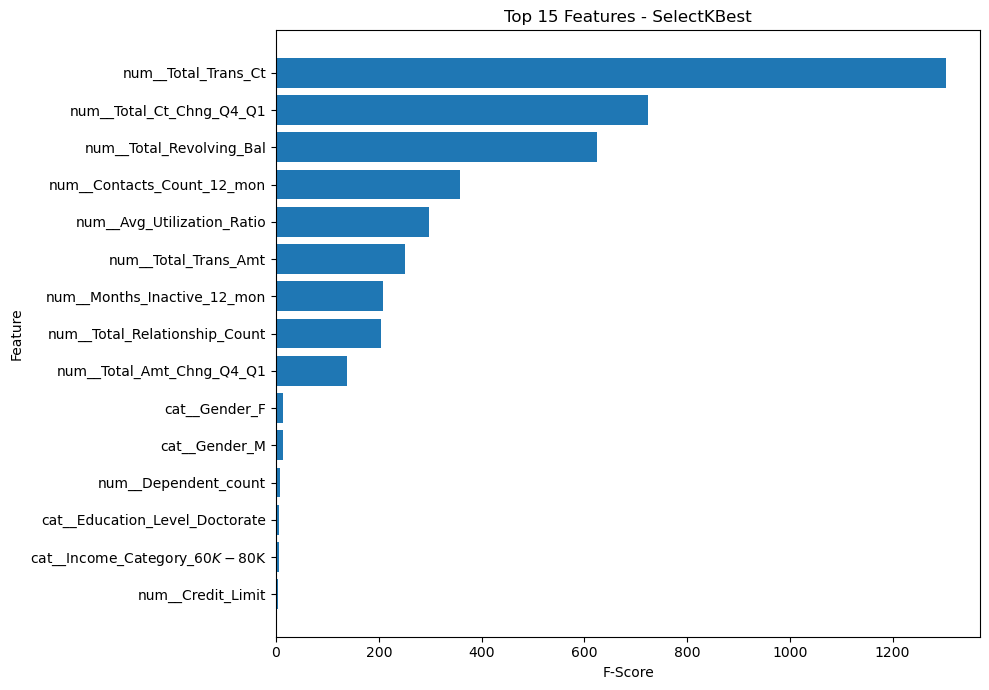

In [104]:
import matplotlib.pyplot as plt

top_kbest = kbest_scores.head(15).sort_values(
    by='F_Score',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_kbest['Feature'],
    top_kbest['F_Score']
)

plt.xlabel('F-Score')
plt.ylabel('Feature')
plt.title('Top 15 Features - SelectKBest')
plt.tight_layout()
plt.show()

Random Forest Feature Importance

Random Forest is used to estimate the importance of each feature.

The 'feature_importances' attribute provides an importance score for each feature based on the fitted forest. Higher values indicate greater contribution to the model's tree-based decisions.

In [105]:
from sklearn.ensemble import RandomForestClassifier

rf_selector = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf_selector.fit(X_train_processed_df, y_train)

# Create feature importance table
rf_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_selector.feature_importances_
})

# Sort from highest to lowest
rf_importance = rf_importance.sort_values(
    by='Importance',
    ascending=False
)

rf_importance.head(20)

,Feature,Importance
10,num__Total_Trans_Amt,0.200375
11,num__Total_Trans_Ct,0.189512
7,num__Total_Revolving_Bal,0.111840
12,num__Total_Ct_Chng_Q4_Q1,0.097945
13,num__Avg_Utilization_Ratio,0.062523
9,num__Total_Amt_Chng_Q4_Q1,0.060352
3,num__Total_Relationship_Count,0.045682
8,num__Avg_Open_To_Buy,0.031217
4,num__Months_Inactive_12_mon,0.030040
6,num__Credit_Limit,0.029843


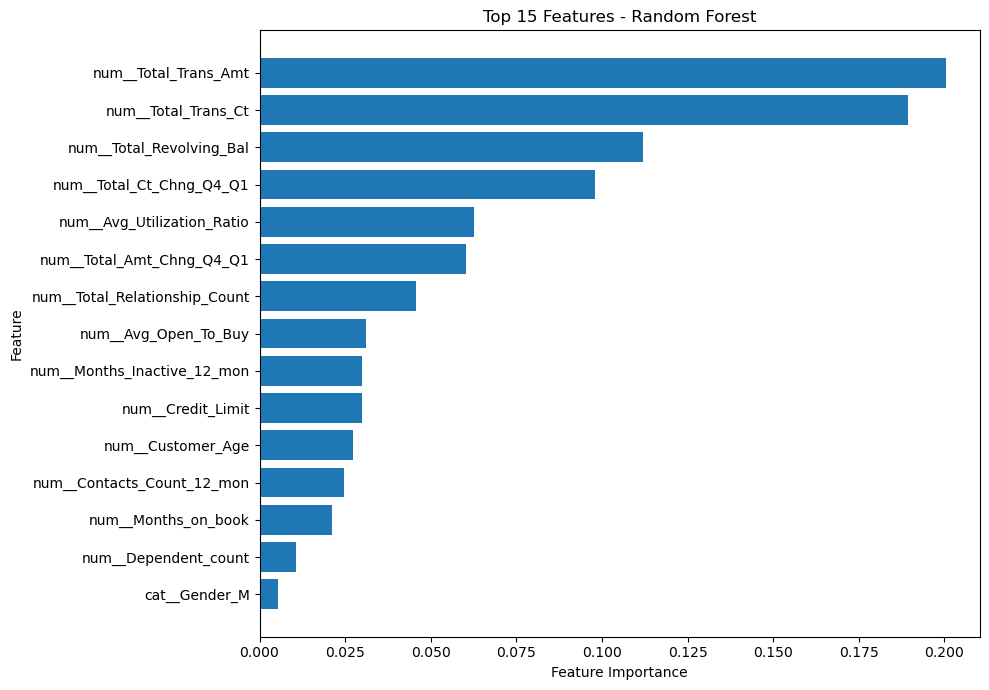

In [106]:
top_rf = rf_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_rf['Feature'],
    top_rf['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 15 Features - Random Forest')
plt.tight_layout()
plt.show()

Comparison of Feature Selection Methods

The rankings obtained from SelectKBest and Random Forest are compared to identify features that consistently appear as important.

SelectKBest evaluates each feature individually based on its statistical relationship with the target, while Random Forest evaluates feature importance within a nonlinear tree-based model.

In [107]:
# Top 15 features from SelectKBest
kbest_top_features = set(
    kbest_scores.head(15)['Feature']
)

# Top 15 features from Random Forest
rf_top_features = set(
    rf_importance.head(15)['Feature']
)

# Features common to both methods
common_features = sorted(
    kbest_top_features.intersection(rf_top_features)
)

print("Features selected by both methods:")
print()

for feature in common_features:
    print(feature)

print("Number of common features:", len(common_features))

Features selected by both methods:

cat__Gender_M
num__Avg_Utilization_Ratio
num__Contacts_Count_12_mon
num__Credit_Limit
num__Dependent_count
num__Months_Inactive_12_mon
num__Total_Amt_Chng_Q4_Q1
num__Total_Ct_Chng_Q4_Q1
num__Total_Relationship_Count
num__Total_Revolving_Bal
num__Total_Trans_Amt
num__Total_Trans_Ct
Number of common features: 12


In [108]:
# Normalize SelectKBest F-scores
kbest_rank = kbest_scores.copy()

kbest_rank['KBest_Rank'] = (
    kbest_rank['F_Score']
    .rank(method='min', ascending=False)
)

# Random Forest ranking
rf_rank = rf_importance.copy()

rf_rank['RF_Rank'] = (
    rf_rank['Importance']
    .rank(method='min', ascending=False)
)

# Combine rankings
feature_comparison = pd.merge(
    kbest_rank[['Feature', 'F_Score', 'KBest_Rank']],
    rf_rank[['Feature', 'Importance', 'RF_Rank']],
    on='Feature'
)

# Average rank
feature_comparison['Average_Rank'] = (
    feature_comparison['KBest_Rank'] +
    feature_comparison['RF_Rank']
) / 2

feature_comparison = feature_comparison.sort_values(
    by='Average_Rank'
)

feature_comparison.head(20)

,Feature,F_Score,KBest_Rank,Importance,RF_Rank,Average_Rank
0,num__Total_Trans_Ct,1304.840615,1.0,0.189512,2.0,1.5
1,num__Total_Ct_Chng_Q4_Q1,724.081801,2.0,0.097945,4.0,3.0
2,num__Total_Revolving_Bal,624.638229,3.0,0.111840,3.0,3.0
5,num__Total_Trans_Amt,251.300721,6.0,0.200375,1.0,3.5
4,num__Avg_Utilization_Ratio,298.439252,5.0,0.062523,5.0,5.0
7,num__Total_Relationship_Count,204.922922,8.0,0.045682,7.0,7.5
8,num__Total_Amt_Chng_Q4_Q1,137.395987,9.0,0.060352,6.0,7.5
3,num__Contacts_Count_12_mon,357.053749,4.0,0.024708,12.0,8.0
6,num__Months_Inactive_12_mon,207.190324,7.0,0.030040,9.0,8.0
9,cat__Gender_M,14.317816,10.0,0.005372,15.0,12.5


In [109]:
# Select top 20 features using SelectKBest
k = 20

select_kbest_final = SelectKBest(
    score_func=f_classif,
    k=k
)

X_train_selected = select_kbest_final.fit_transform(
    X_train_processed_df,
    y_train
)

X_test_selected = select_kbest_final.transform(
    X_test_processed_df
)

selected_feature_names = (
    select_kbest_final.get_feature_names_out(feature_names)
)

print("Original number of features:",
      X_train_processed_df.shape[1])

print("Selected number of features:",
      X_train_selected.shape[1])

print("Selected features:")
for feature in selected_feature_names:
    print(feature)

Original number of features: 37
Selected number of features: 20
Selected features:
num__Customer_Age
num__Dependent_count
num__Total_Relationship_Count
num__Months_Inactive_12_mon
num__Contacts_Count_12_mon
num__Credit_Limit
num__Total_Revolving_Bal
num__Total_Amt_Chng_Q4_Q1
num__Total_Trans_Amt
num__Total_Trans_Ct
num__Total_Ct_Chng_Q4_Q1
num__Avg_Utilization_Ratio
cat__Gender_F
cat__Gender_M
cat__Education_Level_Doctorate
cat__Marital_Status_Married
cat__Marital_Status_Single
cat__Income_Category_$60K - $80K
cat__Income_Category_$80K - $120K
cat__Income_Category_Less than $40K


In [110]:
X_train_selected_df = pd.DataFrame(
    X_train_selected,
    columns=selected_feature_names,
    index=X_train_processed_df.index
)

X_test_selected_df = pd.DataFrame(
    X_test_selected,
    columns=selected_feature_names,
    index=X_test_processed_df.index
)

print("Selected training data shape:",
      X_train_selected_df.shape)

print("Selected testing data shape:",
      X_test_selected_df.shape)

Selected training data shape: (8101, 20)
Selected testing data shape: (2026, 20)


In [111]:
print("===== FEATURE SELECTION SUMMARY =====")

print("Original processed features:",
      X_train_processed_df.shape[1])

print("Selected features:",
      X_train_selected_df.shape[1])

print("Training samples:",
      X_train_selected_df.shape[0])

print("Testing samples:",
      X_test_selected_df.shape[0])

print("Selected feature names:")
print(list(selected_feature_names))

===== FEATURE SELECTION SUMMARY =====
Original processed features: 37
Selected features: 20
Training samples: 8101
Testing samples: 2026
Selected feature names:
['num__Customer_Age', 'num__Dependent_count', 'num__Total_Relationship_Count', 'num__Months_Inactive_12_mon', 'num__Contacts_Count_12_mon', 'num__Credit_Limit', 'num__Total_Revolving_Bal', 'num__Total_Amt_Chng_Q4_Q1', 'num__Total_Trans_Amt', 'num__Total_Trans_Ct', 'num__Total_Ct_Chng_Q4_Q1', 'num__Avg_Utilization_Ratio', 'cat__Gender_F', 'cat__Gender_M', 'cat__Education_Level_Doctorate', 'cat__Marital_Status_Married', 'cat__Marital_Status_Single', 'cat__Income_Category_$60K - $80K', 'cat__Income_Category_$80K - $120K', 'cat__Income_Category_Less than $40K']


In [112]:
print("========== FINAL PART 4 & 5 CHECK ==========")

print("Clean dataset shape:", df.shape)
print("X shape:", X.shape)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nProcessed training shape:", X_train_processed_df.shape)
print("Processed testing shape:", X_test_processed_df.shape)

print("\nSelected training shape:", X_train_selected_df.shape)
print("Selected testing shape:", X_test_selected_df.shape)

print("\nTarget values:")
print(y.value_counts())

print("\nSelected features:")
print(list(selected_feature_names))

========== FINAL PART 4 & 5 CHECK ==========
Clean dataset shape: (10127, 20)
X shape: (10127, 19)
Training shape: (8101, 19)
Testing shape: (2026, 19)

Processed training shape: (8101, 37)
Processed testing shape: (2026, 37)

Selected training shape: (8101, 20)
Selected testing shape: (2026, 20)

Target values:
Attrition_Flag
0    8500
1    1627
Name: count, dtype: int64

Selected features:
['num__Customer_Age', 'num__Dependent_count', 'num__Total_Relationship_Count', 'num__Months_Inactive_12_mon', 'num__Contacts_Count_12_mon', 'num__Credit_Limit', 'num__Total_Revolving_Bal', 'num__Total_Amt_Chng_Q4_Q1', 'num__Total_Trans_Amt', 'num__Total_Trans_Ct', 'num__Total_Ct_Chng_Q4_Q1', 'num__Avg_Utilization_Ratio', 'cat__Gender_F', 'cat__Gender_M', 'cat__Education_Level_Doctorate', 'cat__Marital_Status_Married', 'cat__Marital_Status_Single', 'cat__Income_Category_$60K - $80K', 'cat__Income_Category_$80K - $120K', 'cat__Income_Category_Less than $40K']


## Feature Selection Conclusion

Feature selection was performed using SelectKBest with the ANOVA F-test and Random Forest feature importance.

SelectKBest ranked features according to their statistical association with customer attrition, while Random Forest identified features that were important within a tree-based classification model.

The feature rankings from both methods were compared, and the top 20 features from SelectKBest were retained for subsequent model development.

Feature selection helps reduce the dimensionality of the processed dataset while retaining the most relevant predictive information.

===========================================================================================================

## MODEL BUILDING

===========================================================================================================

In this stage, multiple classification algorithms are developed to predict customer attrition.

The following five machine learning classification algorithms are implemented:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. K-Nearest Neighbors Classifier
5. Gradient Boosting Classifier

The models are trained using the selected features obtained during the feature selection stage.


In [113]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

print("All model libraries imported successfully!")

All model libraries imported successfully!


In [114]:
# Define classification models

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ),

    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Gradient Boosting': GradientBoostingClassifier(
        random_state=42
    )
}

print("Number of models:", len(models))
print("\nModels:")
for name in models:
    print("-", name)

Number of models: 5

Models:
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors
- Gradient Boosting


In [115]:
# Train all models

trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    
    model.fit(
        X_train_selected_df,
        y_train
    )
    
    trained_models[name] = model

print("All models trained successfully!")

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training K-Nearest Neighbors...
Training Gradient Boosting...
All models trained successfully!


In [116]:
# Generate predictions for each model

predictions = {}

for name, model in trained_models.items():
    predictions[name] = model.predict(X_test_selected_df)

print("Predictions generated for all models.")

Predictions generated for all models.


In [117]:
for name, pred in predictions.items():
    print(
        f"{name}:",
        len(pred),
        "predictions"
    )

Logistic Regression: 2026 predictions
Decision Tree: 2026 predictions
Random Forest: 2026 predictions
K-Nearest Neighbors: 2026 predictions
Gradient Boosting: 2026 predictions


In [118]:
from sklearn.metrics import accuracy_score

model_accuracy = {}

for name, pred in predictions.items():
    accuracy = accuracy_score(
        y_test,
        pred
    )
    
    model_accuracy[name] = accuracy

print("Model Accuracy:")
print()

for name, accuracy in model_accuracy.items():
    print(
        f"{name}: {accuracy:.4f}"
    )

Model Accuracy:

Logistic Regression: 0.8539
Decision Tree: 0.9339
Random Forest: 0.9580
K-Nearest Neighbors: 0.9205
Gradient Boosting: 0.9630


In [119]:
model_comparison = pd.DataFrame({
    'Model': list(model_accuracy.keys()),
    'Accuracy': list(model_accuracy.values())
})

model_comparison = model_comparison.sort_values(
    by='Accuracy',
    ascending=False
).reset_index(drop=True)

model_comparison

,Model,Accuracy
0,Gradient Boosting,0.962981
1,Random Forest,0.958045
2,Decision Tree,0.933860
3,K-Nearest Neighbors,0.920533
4,Logistic Regression,0.853899


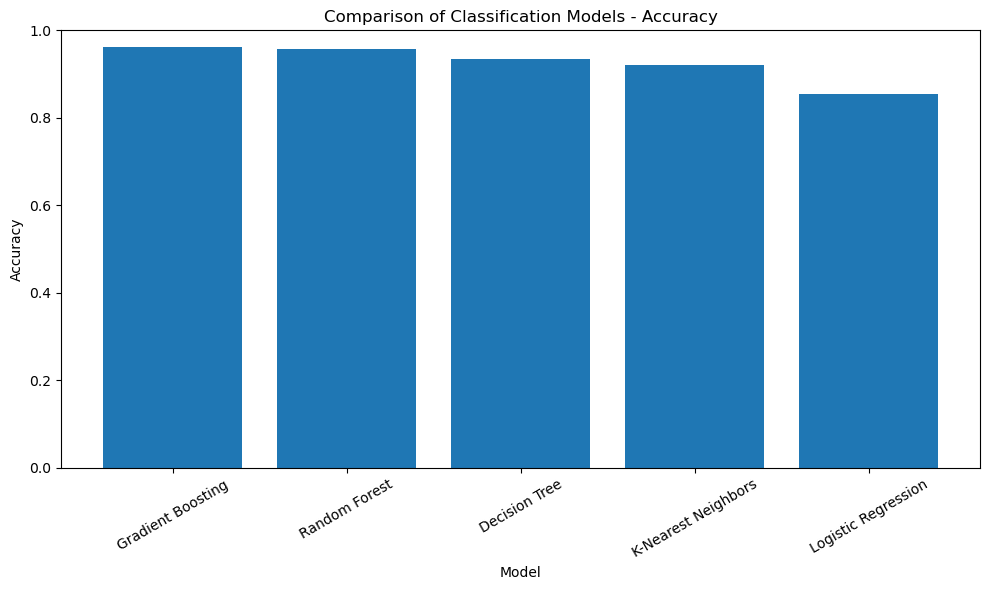

In [120]:
plt.figure(figsize=(10, 6))

plt.bar(
    model_comparison['Model'],
    model_comparison['Accuracy']
)

plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('Comparison of Classification Models - Accuracy')

plt.xticks(rotation=30)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

# Model Building Conclusion

Five classification algorithms were trained using the selected features:

- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors
- Gradient Boosting

Predictions were generated on the test dataset and the initial accuracy of each model was compared.

Accuracy alone is not sufficient for evaluating this customer churn problem because the target classes are imbalanced. Therefore, precision, recall, F1-score, confusion matrix and ROC-AUC will be evaluated in the next stage.

===========================================================================================================

## MODEL EVALUATION

===========================================================================================================

The performance of the classification models is evaluated using multiple classification metrics.

The following metrics are used:

- Accuracy
- Precision
- Recall
- F1-Score
- Confusion Matrix
- ROC-AUC

Since the dataset contains an imbalanced target variable, accuracy alone is not sufficient to determine the best model. Precision, recall and F1-score for the attrited customer class are also considered.

In [121]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [122]:
evaluation_results = []

for name, pred in predictions.items():

    accuracy = accuracy_score(y_test, pred)

    precision = precision_score(
        y_test,
        pred,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        pred,
        pos_label=1,
        zero_division=0
    )

    evaluation_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

evaluation_results_df = pd.DataFrame(evaluation_results)

evaluation_results_df = evaluation_results_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

evaluation_results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Gradient Boosting,0.962981,0.959559,0.803077,0.874372
1,Random Forest,0.958045,0.875000,0.861538,0.868217
2,Decision Tree,0.933860,0.825939,0.744615,0.783172
3,K-Nearest Neighbors,0.920533,0.841667,0.621538,0.715044
4,Logistic Regression,0.853899,0.528942,0.815385,0.641646


Sorting by F1 because F1 balances precision and recall, making it more informative than accuracy alone when we care about correctly identifying churners.

In [123]:
for name, model in trained_models.items():

    print("=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            predictions[name],
            target_names=[
                'Existing Customer',
                'Attrited Customer'
            ],
            zero_division=0
        )
    )

Logistic Regression
                   precision    recall  f1-score   support

Existing Customer       0.96      0.86      0.91      1701
Attrited Customer       0.53      0.82      0.64       325

         accuracy                           0.85      2026
        macro avg       0.74      0.84      0.77      2026
     weighted avg       0.89      0.85      0.87      2026

Decision Tree
                   precision    recall  f1-score   support

Existing Customer       0.95      0.97      0.96      1701
Attrited Customer       0.83      0.74      0.78       325

         accuracy                           0.93      2026
        macro avg       0.89      0.86      0.87      2026
     weighted avg       0.93      0.93      0.93      2026

Random Forest
                   precision    recall  f1-score   support

Existing Customer       0.97      0.98      0.98      1701
Attrited Customer       0.88      0.86      0.87       325

         accuracy                           0.96      2026


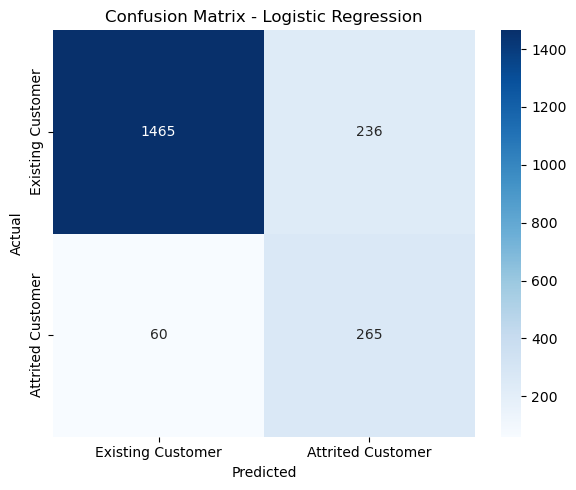

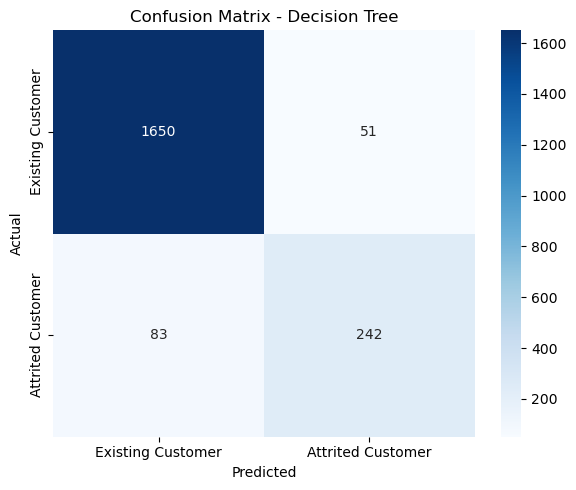

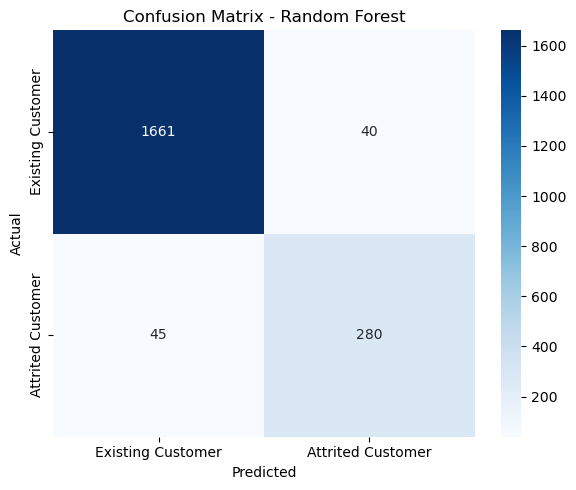

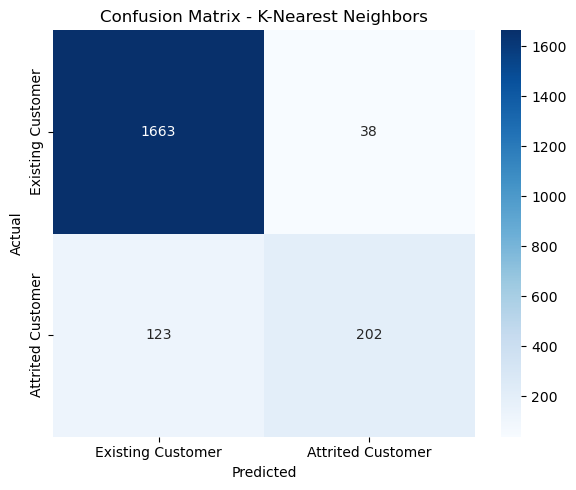

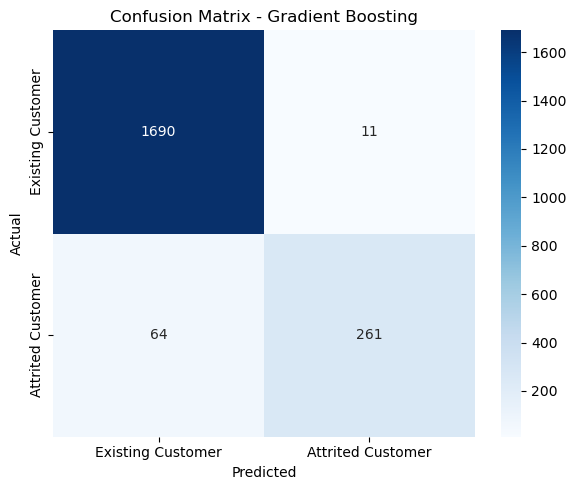

In [124]:
for name, pred in predictions.items():

    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=[
            'Existing Customer',
            'Attrited Customer'
        ],
        yticklabels=[
            'Existing Customer',
            'Attrited Customer'
        ]
    )

    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix - {name}')

    plt.tight_layout()
    plt.show()

In [125]:
roc_auc_results = {}

for name, model in trained_models.items():

    y_probability = model.predict_proba(
        X_test_selected_df
    )[:, 1]

    roc_auc = roc_auc_score(
        y_test,
        y_probability
    )

    roc_auc_results[name] = roc_auc

    print(
        f"{name}: ROC-AUC = {roc_auc:.4f}"
    )

Logistic Regression: ROC-AUC = 0.9207
Decision Tree: ROC-AUC = 0.8573
Random Forest: ROC-AUC = 0.9875
K-Nearest Neighbors: ROC-AUC = 0.9228
Gradient Boosting: ROC-AUC = 0.9865


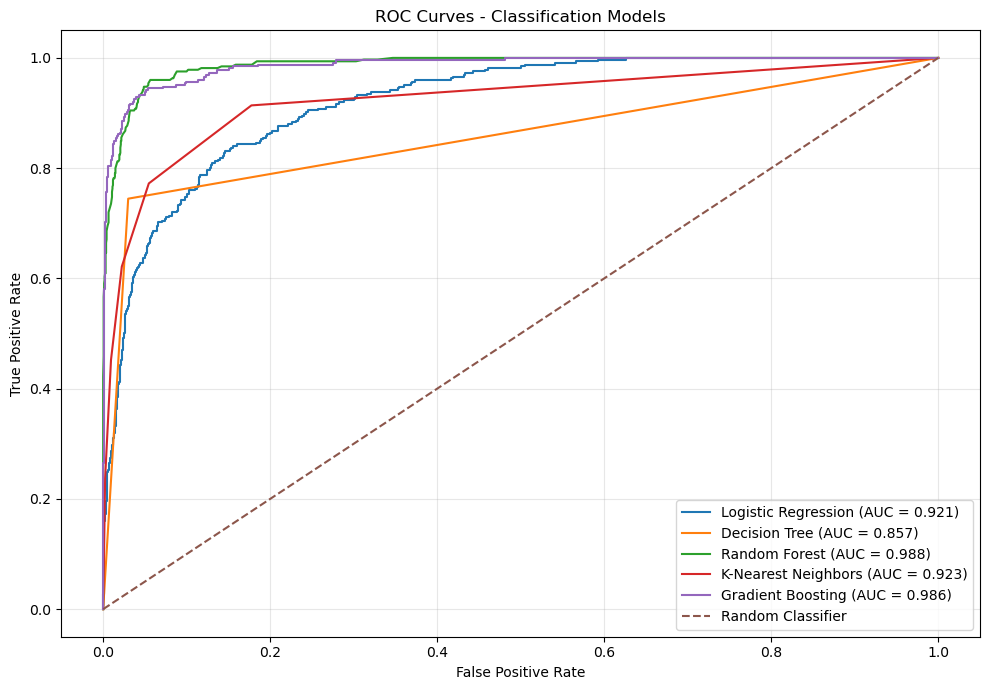

In [126]:
plt.figure(figsize=(10, 7))

for name, model in trained_models.items():

    y_probability = model.predict_proba(
        X_test_selected_df
    )[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_probability
    )

    auc_score = roc_auc_score(
        y_test,
        y_probability
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc_score:.3f})'
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Classification Models')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [127]:
evaluation_results_df['ROC-AUC'] = (
    evaluation_results_df['Model']
    .map(roc_auc_results)
)

evaluation_results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Gradient Boosting,0.962981,0.959559,0.803077,0.874372,0.986455
1,Random Forest,0.958045,0.875000,0.861538,0.868217,0.987532
2,Decision Tree,0.933860,0.825939,0.744615,0.783172,0.857317
3,K-Nearest Neighbors,0.920533,0.841667,0.621538,0.715044,0.922805
4,Logistic Regression,0.853899,0.528942,0.815385,0.641646,0.920678


===========================================================================================================

## HYPERPARAMETER TUNING & PIPELINE

===========================================================================================================

Hyperparameter tuning is performed to improve the performance of the classification models.

Based on the initial model evaluation, Gradient Boosting and Random Forest were selected for further optimization.

GridSearchCV with cross-validation is used to identify suitable hyperparameter combinations.

F1-score is used as the primary scoring metric because the customer attrition dataset is imbalanced.

A Pipeline is used to combine the model with the tuning process in a structured and reproducible workflow.

In [128]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

print("Hyperparameter tuning libraries imported successfully!")

Hyperparameter tuning libraries imported successfully!


In [129]:
rf_pipeline = Pipeline([
    ('model', RandomForestClassifier(
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

print(rf_pipeline)

Pipeline(steps=[('model',
                 RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                        random_state=42))])


In [130]:
rf_param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

print("Random Forest parameter grid created.")

Random Forest parameter grid created.


In [131]:
rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    refit=True,
    verbose=1
)

rf_grid_search.fit(
    X_train_selected_df,
    y_train
)

print("Random Forest tuning completed!")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Random Forest tuning completed!


In [132]:
print("Best Random Forest parameters:")
print(rf_grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(f"{rf_grid_search.best_score_:.4f}")

Best Random Forest parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Best cross-validation F1-score:
0.8862


In [133]:
gb_pipeline = Pipeline([
    ('model', GradientBoostingClassifier(
        random_state=42
    ))
])

print(gb_pipeline)

Pipeline(steps=[('model', GradientBoostingClassifier(random_state=42))])


In [134]:
gb_param_grid = {
    'model__n_estimators': [100, 200],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3, 4],
    'model__min_samples_split': [2, 5]
}

print("Gradient Boosting parameter grid created.")

Gradient Boosting parameter grid created.


In [135]:
gb_grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    refit=True,
    verbose=1
)

gb_grid_search.fit(
    X_train_selected_df,
    y_train
)

print("Gradient Boosting tuning completed!")

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Gradient Boosting tuning completed!


In [136]:
print("Best Gradient Boosting parameters:")
print(gb_grid_search.best_params_)

print("Best cross-validation F1-score:")
print(f"{gb_grid_search.best_score_:.4f}")

Best Gradient Boosting parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 4, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best cross-validation F1-score:
0.9129


In [137]:
tuning_results = pd.DataFrame({
    'Model': [
        'Random Forest',
        'Gradient Boosting'
    ],
    'Best CV F1-Score': [
        rf_grid_search.best_score_,
        gb_grid_search.best_score_
    ]
})

tuning_results = tuning_results.sort_values(
    by='Best CV F1-Score',
    ascending=False
).reset_index(drop=True)

tuning_results

,Model,Best CV F1-Score
0,Gradient Boosting,0.912943
1,Random Forest,0.886245


In [138]:
# Predictions from tuned models

rf_tuned_pred = rf_grid_search.predict(
    X_test_selected_df
)

gb_tuned_pred = gb_grid_search.predict(
    X_test_selected_df
)

print("Tuned model predictions generated successfully!")

Tuned model predictions generated successfully!


In [139]:
tuned_model_results = []

tuned_predictions = {
    'Tuned Random Forest': rf_tuned_pred,
    'Tuned Gradient Boosting': gb_tuned_pred
}

for name, pred in tuned_predictions.items():

    accuracy = accuracy_score(
        y_test,
        pred
    )

    precision = precision_score(
        y_test,
        pred,
        pos_label=1,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        pred,
        pos_label=1,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        pred,
        pos_label=1,
        zero_division=0
    )

    tuned_model_results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

tuned_results_df = pd.DataFrame(
    tuned_model_results
)

tuned_results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Tuned Random Forest,0.957552,0.865443,0.870769,0.868098
1,Tuned Gradient Boosting,0.967917,0.951389,0.843077,0.893964


In [140]:
rf_tuned_probability = rf_grid_search.predict_proba(
    X_test_selected_df
)[:, 1]

gb_tuned_probability = gb_grid_search.predict_proba(
    X_test_selected_df
)[:, 1]

rf_tuned_auc = roc_auc_score(
    y_test,
    rf_tuned_probability
)

gb_tuned_auc = roc_auc_score(
    y_test,
    gb_tuned_probability
)

tuned_results_df['ROC-AUC'] = [
    rf_tuned_auc,
    gb_tuned_auc
]

tuned_results_df

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Random Forest,0.957552,0.865443,0.870769,0.868098,0.987555
1,Tuned Gradient Boosting,0.967917,0.951389,0.843077,0.893964,0.991703


In [141]:
final_model_comparison = pd.concat(
    [
        evaluation_results_df,
        tuned_results_df
    ],
    ignore_index=True
)

final_model_comparison = final_model_comparison.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

final_model_comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Tuned Gradient Boosting,0.967917,0.951389,0.843077,0.893964,0.991703
1,Gradient Boosting,0.962981,0.959559,0.803077,0.874372,0.986455
2,Random Forest,0.958045,0.875000,0.861538,0.868217,0.987532
3,Tuned Random Forest,0.957552,0.865443,0.870769,0.868098,0.987555
4,Decision Tree,0.933860,0.825939,0.744615,0.783172,0.857317
5,K-Nearest Neighbors,0.920533,0.841667,0.621538,0.715044,0.922805
6,Logistic Regression,0.853899,0.528942,0.815385,0.641646,0.920678


In [142]:
best_model_row = tuned_results_df.loc[
    tuned_results_df['F1-Score'].idxmax()
]

print("Best tuned model:")
print(best_model_row['Model'])

print("Performance:")
print(best_model_row)

Best tuned model:
Tuned Gradient Boosting
Performance:
Model        Tuned Gradient Boosting
Accuracy                    0.967917
Precision                   0.951389
Recall                      0.843077
F1-Score                    0.893964
ROC-AUC                     0.991703
Name: 1, dtype: object


## Hyperparameter Tuning Conclusion

Hyperparameter tuning was performed for the Random Forest and Gradient Boosting classifiers using GridSearchCV with 5-fold cross-validation.

F1-score was selected as the primary optimization metric because the customer attrition dataset contains an imbalanced target variable.

The tuned models were subsequently evaluated on the held-out test dataset using accuracy, precision, recall, F1-score and ROC-AUC.

The best-performing tuned model will be selected as the final model for deployment and unseen-data testing.

===========================================================================================================

## SAVE THE FINAL MODEL

===========================================================================================================

The best-performing tuned model is saved for future predictions and unseen-data testing.

The final saved object contains:
- Data preprocessing
- Feature selection
- The best tuned classification model
- Selected feature names
- Model information

This allows the same preprocessing and feature selection steps to be applied when making predictions on new customer data.

In [143]:
import joblib
import os

print("Joblib imported successfully!")

Joblib imported successfully!


In [144]:
# Identify the best tuned model based on F1-score

best_model_name = best_model_row['Model']

if best_model_name == 'Tuned Random Forest':
    best_tuned_model = rf_grid_search.best_estimator_
elif best_model_name == 'Tuned Gradient Boosting':
    best_tuned_model = gb_grid_search.best_estimator_

print("Final Model Selected:")
print(best_model_name)

Final Model Selected:
Tuned Gradient Boosting


In [145]:
print("Final model parameters:")
print(best_tuned_model)

Final model parameters:
Pipeline(steps=[('model',
                 GradientBoostingClassifier(max_depth=4, min_samples_split=5,
                                            n_estimators=200,
                                            random_state=42))])


In [146]:
final_model_package = {
    'preprocessor': preprocessor,
    'feature_selector': select_kbest_final,
    'model': best_tuned_model,
    'selected_feature_names': list(selected_feature_names),
    'model_name': best_model_name
}

print("Final model package created successfully!")

Final model package created successfully!


In [147]:
model_filename = "credit_card_customer_churn_final_model.joblib"

joblib.dump(
    final_model_package,
    model_filename
)

print("Final model saved successfully!")
print("File name:", model_filename)
print("File location:", os.path.abspath(model_filename))

Final model saved successfully!
File name: credit_card_customer_churn_final_model.joblib
File location: c:\Users\silpa\Downloads\Assignment_Eti\Assignments_Eti\credit_card_customer_churn_final_model.joblib


In [148]:
loaded_model_package = joblib.load(model_filename)

print("Saved model loaded successfully!")
print("Model name:", loaded_model_package['model_name'])
print("Number of selected features:",
      len(loaded_model_package['selected_feature_names']))

Saved model loaded successfully!
Model name: Tuned Gradient Boosting
Number of selected features: 20


In [149]:
loaded_model = loaded_model_package['model']

loaded_predictions = loaded_model.predict(
    X_test_selected_df
)

print("Predictions generated using the saved model.")

print("First 10 predictions:")
print(loaded_predictions[:10])

Predictions generated using the saved model.
First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]


In [150]:
loaded_accuracy = accuracy_score(
    y_test,
    loaded_predictions
)

loaded_precision = precision_score(
    y_test,
    loaded_predictions,
    zero_division=0
)

loaded_recall = recall_score(
    y_test,
    loaded_predictions,
    zero_division=0
)

loaded_f1 = f1_score(
    y_test,
    loaded_predictions,
    zero_division=0
)

print("===== SAVED MODEL PERFORMANCE =====")
print(f"Accuracy  : {loaded_accuracy:.4f}")
print(f"Precision : {loaded_precision:.4f}")
print(f"Recall    : {loaded_recall:.4f}")
print(f"F1-Score  : {loaded_f1:.4f}")

===== SAVED MODEL PERFORMANCE =====
Accuracy  : 0.9679
Precision : 0.9514
Recall    : 0.8431
F1-Score  : 0.8940


## Save Model Conclusion

The best-performing tuned classification model was selected based on F1-score.

The final model package was saved using Joblib. The package contains the preprocessing transformer, SelectKBest feature selector, trained model, selected feature names, and model name.

The saved model was successfully loaded and used to generate predictions on the test dataset. The performance of the loaded model was consistent with the previously evaluated tuned model.

The saved model can now be used for testing on unseen customer data.

===========================================================================================================

## TEST WITH UNSEEN DATA

===========================================================================================================

The saved Gradient Boosting model is tested on new customer records that were not used during model training or evaluation.

The unseen customer data does not contain the target variable, Attrition_Flag.

The same preprocessing and feature-selection steps used during model development are applied before generating predictions.

In [151]:
# Create unseen customer data

unseen_data = pd.DataFrame({
    'Customer_Age': [35, 52, 29],
    'Gender': ['F', 'M', 'F'],
    'Dependent_count': [2, 3, 0],
    'Education_Level': ['Graduate', 'High School', 'Graduate'],
    'Marital_Status': ['Married', 'Married', 'Single'],
    'Income_Category': ['$40K - $60K', '$80K - $120K', 'Less than $40K'],
    'Card_Category': ['Blue', 'Blue', 'Silver'],
    'Months_on_book': [36, 45, 24],
    'Total_Relationship_Count': [4, 3, 2],
    'Months_Inactive_12_mon': [1, 3, 4],
    'Contacts_Count_12_mon': [1, 3, 4],
    'Credit_Limit': [5000.0, 12000.0, 2500.0],
    'Total_Revolving_Bal': [1500, 2500, 500],
    'Avg_Open_To_Buy': [3500.0, 9500.0, 2000.0],
    'Total_Amt_Chng_Q4_Q1': [0.70, 0.95, 0.55],
    'Total_Trans_Amt': [2500, 4500, 1800],
    'Total_Trans_Ct': [50, 75, 35],
    'Total_Ct_Chng_Q4_Q1': [0.70, 0.85, 0.50],
    'Avg_Utilization_Ratio': [0.30, 0.25, 0.45]
})

print("Unseen data created successfully.")
print("Shape:", unseen_data.shape)

display(unseen_data)

Unseen data created successfully.
Shape: (3, 19)


,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,35,F,2,Graduate,Married,$40K - $60K,Blue,36,4,1,1,5000.0,1500,3500.0,0.70,2500,50,0.70,0.30
1,52,M,3,High School,Married,$80K - $120K,Blue,45,3,3,3,12000.0,2500,9500.0,0.95,4500,75,0.85,0.25
2,29,F,0,Graduate,Single,Less than $40K,Silver,24,2,4,4,2500.0,500,2000.0,0.55,1800,35,0.50,0.45


In [152]:
# Apply the previously fitted preprocessing steps

unseen_processed = preprocessor.transform(unseen_data)

unseen_processed_df = pd.DataFrame(
    unseen_processed,
    columns=feature_names,
    index=unseen_data.index
)

print("Unseen data preprocessing completed.")
print("Processed shape:", unseen_processed_df.shape)

Unseen data preprocessing completed.
Processed shape: (3, 37)


In [153]:
# Apply the previously fitted SelectKBest feature selector

unseen_selected = select_kbest_final.transform(
    unseen_processed_df
)

unseen_selected_df = pd.DataFrame(
    unseen_selected,
    columns=selected_feature_names,
    index=unseen_data.index
)

print("Feature selection completed.")
print("Selected shape:", unseen_selected_df.shape)

Feature selection completed.
Selected shape: (3, 20)


In [154]:
# Generate predictions using the saved final model

unseen_predictions = loaded_model.predict(
    unseen_selected_df
)

print("Predictions generated successfully.")
print(unseen_predictions)

Predictions generated successfully.
[0 0 1]


In [155]:
# Generate churn probabilities

unseen_probabilities = loaded_model.predict_proba(
    unseen_selected_df
)[:, 1]

print("Churn probabilities:")
print(unseen_probabilities)

Churn probabilities:
[0.02773614 0.00609888 0.95551326]


In [156]:
# Create final unseen-data prediction table

unseen_results = unseen_data.copy()

unseen_results['Predicted_Attrition'] = unseen_predictions
unseen_results['Churn_Probability'] = unseen_probabilities

unseen_results['Predicted_Status'] = unseen_results[
    'Predicted_Attrition'
].map({
    0: 'Existing Customer',
    1: 'Attrited Customer'
})

display(
    unseen_results[
        [
            'Customer_Age',
            'Gender',
            'Credit_Limit',
            'Total_Trans_Amt',
            'Total_Trans_Ct',
            'Predicted_Status',
            'Churn_Probability'
        ]
    ]
)

,Customer_Age,Gender,Credit_Limit,Total_Trans_Amt,Total_Trans_Ct,Predicted_Status,Churn_Probability
0,35,F,5000.0,2500,50,Existing Customer,0.027736
1,52,M,12000.0,4500,75,Existing Customer,0.006099
2,29,F,2500.0,1800,35,Attrited Customer,0.955513


## Unseen Data Interpretation

The final tuned Gradient Boosting model was applied to three new customer records.

The model generated an attrition prediction and churn probability for each customer.

A prediction of 1 represents an Attrited Customer, while a prediction of 0 represents an Existing Customer.

The churn probability indicates the model's estimated likelihood that a customer belongs to the attrited class.

These predictions demonstrate how the saved machine learning model can be used to identify customers who may be at higher risk of churn.

===========================================================================================================

## INTERPRETATION & CONCLUSION

===========================================================================================================

The final selected model is the tuned Gradient Boosting Classifier.

The model achieved the following performance on the test dataset:

- Accuracy: 96.79%
- Precision: 95.14%
- Recall: 84.31%
- F1-Score: 89.40%

The model demonstrates strong predictive performance in identifying customers who are likely to churn.

## Business Interpretation

The objective of this project was to develop a machine learning model capable of predicting credit card customer attrition.

The tuned Gradient Boosting model achieved a high F1-score of 89.40%, indicating a good balance between precision and recall.

The model can help a bank identify customers who have a higher probability of leaving the service. Such customers can be targeted with appropriate retention strategies, personalized offers, improved customer service, or engagement campaigns.

From the unseen-data test, the model identified one of the three new customers as having a high probability of churn (95.55%). This demonstrates how the model can be used to identify potentially high-risk customers.

## Key Findings

1. Customer attrition is an important classification problem in the credit card industry.

2. The dataset contains an imbalanced target variable, with Existing Customers representing the majority class.

3. Customer transaction behaviour, inactivity, contact frequency, relationship information, and other financial characteristics provide useful information for predicting attrition.

4. Feature selection using SelectKBest helped reduce the processed feature set from 37 features to 20 selected features.

5. Five classification algorithms were evaluated:
   - Logistic Regression
   - Decision Tree
   - Random Forest
   - K-Nearest Neighbors
   - Gradient Boosting

6. Hyperparameter tuning was performed for Random Forest and Gradient Boosting using GridSearchCV.

7. The tuned Gradient Boosting model was selected as the final model based on its F1-score.

8. The final model achieved 96.79% accuracy and an F1-score of 89.40%.

9. The saved model was successfully loaded and tested on unseen customer data.

## Limitations

1. The dataset represents a specific credit card customer population and may not represent customers from every bank or geographic region.

2. The target variable is imbalanced, with significantly more existing customers than attrited customers.

3. The unseen-data demonstration uses a small number of newly created customer records rather than a large independent real-world dataset.

4. The model identifies statistical patterns and associations in the available data. The predictions should not be interpreted as proof of causal relationships.

5. Customer behaviour can change over time, so the model may require periodic retraining with newer customer data.

## Final Conclusion

This project successfully developed a machine learning-based customer churn prediction system using the Credit Card Customers dataset.

The data was cleaned, explored, preprocessed, encoded, scaled, and subjected to feature selection. Multiple classification algorithms were trained and evaluated using appropriate classification metrics.

Hyperparameter tuning improved the selected model, and the tuned Gradient Boosting Classifier was chosen as the final model. It achieved an accuracy of 96.79%, precision of 95.14%, recall of 84.31%, and F1-score of 89.40% on the test dataset.

The final model was saved using Joblib and successfully tested on unseen customer records. The results demonstrate that machine learning can be used as a useful tool for identifying customers who may be at risk of credit card attrition.

Therefore, the developed model can support customer retention strategies by helping organizations identify potentially high-risk customers and take proactive measures.

===========================================================================================================

## FUTURE WORK

===========================================================================================================


## Future Work

Although the developed Gradient Boosting model achieved strong predictive performance, several improvements can be explored in the future.

### 1. Explore Deep Learning Algorithms

Deep learning models such as Artificial Neural Networks (ANNs) can be explored to determine whether they can improve customer churn prediction performance.

### 2. Periodic Model Updating

Customer behaviour and financial patterns can change over time. Therefore, the model can be periodically retrained using newer customer data to maintain its predictive performance.

### 3. Address Class Imbalance

The dataset contains considerably more existing customers than attrited customers. Future work can investigate resampling techniques such as SMOTE, oversampling, or undersampling to improve the model's ability to identify minority-class customers.

### 4. Add More Features

Additional customer-related features can be incorporated into future versions of the model. Examples may include customer service interactions, transaction frequency, payment behaviour, spending patterns, and other relevant financial or behavioural information.

### 5. Continuous Model Evaluation

The model can be continuously evaluated using new data and appropriate classification metrics such as precision, recall, F1-score, and ROC-AUC to ensure that its performance remains reliable.

### 6. Model Deployment

The final model can be integrated into a web application or banking decision-support system. This could allow authorized users to enter customer information and receive a churn-risk prediction.

# FINAL PROJECT SUMMARY

This project developed a machine learning-based Credit Card Customer Churn Prediction System.

The project followed the complete machine learning workflow, including:

- Problem definition
- Data collection
- Data cleaning and preprocessing
- Exploratory Data Analysis
- Feature engineering
- Feature selection
- Train-test splitting
- Feature scaling
- Multiple machine learning models
- Model evaluation
- Hyperparameter tuning
- Model saving
- Testing with unseen data
- Interpretation and conclusion
- Future work

Five classification algorithms were evaluated, and hyperparameter tuning was performed for Random Forest and Gradient Boosting.

The tuned Gradient Boosting Classifier was selected as the final model. It achieved:

- Accuracy: 96.79%
- Precision: 95.14%
- Recall: 84.31%
- F1-Score: 89.40%

The final model was successfully saved using Joblib and tested on unseen customer records.

The developed system demonstrates how machine learning can assist in identifying customers who may be at risk of credit card attrition and can support data-driven customer retention strategies.